# Resultados

Classificação de perfis associados à hiperglicemia crônica clinicamente significativa (HbA1c ≥ 6,5%) na Subamostra Laboratorial da PNS 2013.

Este notebook só orquestra. A lógica fica em `src/`. É o texto da arguição e a fonte das figuras do LaTeX: se alguma etapa não puder ser chamada de `src/`, o problema está em `src/`, não aqui.

Para reproduzir pela linha de comando: `python -m src.experimento --figuras` (alvo `make figuras`). As tabelas e figuras abaixo são os mesmos artefatos, gravados em `reports/`.

Dois modelos entram na comparação, a Regressão Logística e a Random Forest, sob o mesmo harness de avaliação e as mesmas partições. Os comparadores não-ML fecham o quadro: a regra clínica da ADA, que é o que a rede faz hoje, e o Dummy de classe majoritária.

In [1]:
import sys
from pathlib import Path

from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import benchmark as bm
from src import colinearidade as col
from src import data as dt
from src import evaluate as ev
from src import experimento as exp
from src import explicabilidade as ex

## Amostra

Do CSV bruto ao conjunto analítico. As exclusões são as do desenho: sem HbA1c válida o registro sai, e nunca é imputado (R3). As contagens vêm de onde o corte acontece; nada é recontado aqui.

As **duas prevalências** medem coisas diferentes. A amostral é o desbalanceamento que `class_weight='balanced'` corrige e o contexto de todas as métricas daqui para frente. A ponderada por `peso_lab` estima parâmetro populacional e só aparece nesta seção: o peso amostral entra na EDA descritiva e não entra no treino de nenhum estimador (R9, D-009, D-031).

In [2]:
analitico = dt.carregar_analitico()
dt.resumo_amostra(analitico)

,item,n,proporcao
0,Linhas no CSV bruto,8952,NaN
1,Duplicadas removidas,0,NaN
2,Excluídas: HbA1c ausente,-411,NaN
3,Excluídas: bloco de medição integralmente ausente,-90,NaN
4,Amostra analítica,8451,NaN
5,"Positivos (HbA1c ≥ 6,5%)",593,0.070169
6,Prevalência ponderada por peso_lab (descritiva),<NA>,0.063575


O split é a primeira operação entre linhas do projeto: nada que olhe para mais de um registro acontece antes dele (R1). 80/20 estratificado pelo alvo, `random_state=42`.

In [3]:
particao = exp.preparar_particao()

print(f"Treino {len(particao.X_tr):>5} registros - prevalencia {particao.y_tr.mean():.4f}")
print(f"Teste  {len(particao.X_te):>5} registros - prevalencia {particao.y_te.mean():.4f}")

Treino  6760 registros - prevalencia 0.0701
Teste   1691 registros - prevalencia 0.0704


Os ausentes remanescentes são os que o `KNNImputer` trata, ajustado só no treino (R2, R3). `colesterol_alto` concentra 15,3% de ausência e é provável MNAR. A categoria explícita "não sabe/não mediu" entra como variante comparada, não como padrão (D-008). Nenhuma contínua tem ausente.

In [4]:
dt.ausentes_por_variavel(analitico, particao.X_tr)

,variavel,ausentes,proporcao,no_treino
0,colesterol_alto,1297,0.153473,1048
1,has_autorrelato,261,0.030884,223
2,regiao,4,0.000473,3
3,raca_cor,2,0.000237,1


## Colinearidade

O protocolo inteiro: Pearson entre as contínuas e VIF sobre a **matriz de design pós-transformação**. Não sobre o bloco numérico cru, que deixaria as compostas fora do diagnóstico e foi o que escondeu a redundância na primeira passagem (D-002).

A chamada abaixo ajusta um preprocessador por conjunto, no treino, e grava os artefatos em `reports/`.

In [5]:
diag = col.diagnostico_completo(particao.X_tr, particao.y_tr)
diag["resumo"]

,feature_set,colunas,vif_maximo,vif_mediano,acima_do_limiar,limiar_vif
0,A_atomico,20,3.512344,1.403028,0,10
1,B_composto,16,3.922227,1.395973,0,10
2,C_completo,23,14.033644,1.623774,2,10


As colunas acima do limiar VIF > 10 são antropométricas nos três conjuntos. As que carregam a redundância de canal (`multimorbidade`, `has_combinada`, `colesterol_sim`) ficam **abaixo** de 10: o VIF não as acusa (D-016).

In [6]:
diag["vif"][diag["vif"]["acima_do_limiar"]]

,feature_set,variavel,vif,r2_auxiliar,acima_do_limiar
36,C_completo,rcest,14.033644,0.928743,True
37,C_completo,circ_cintura,13.732556,0.927180,True


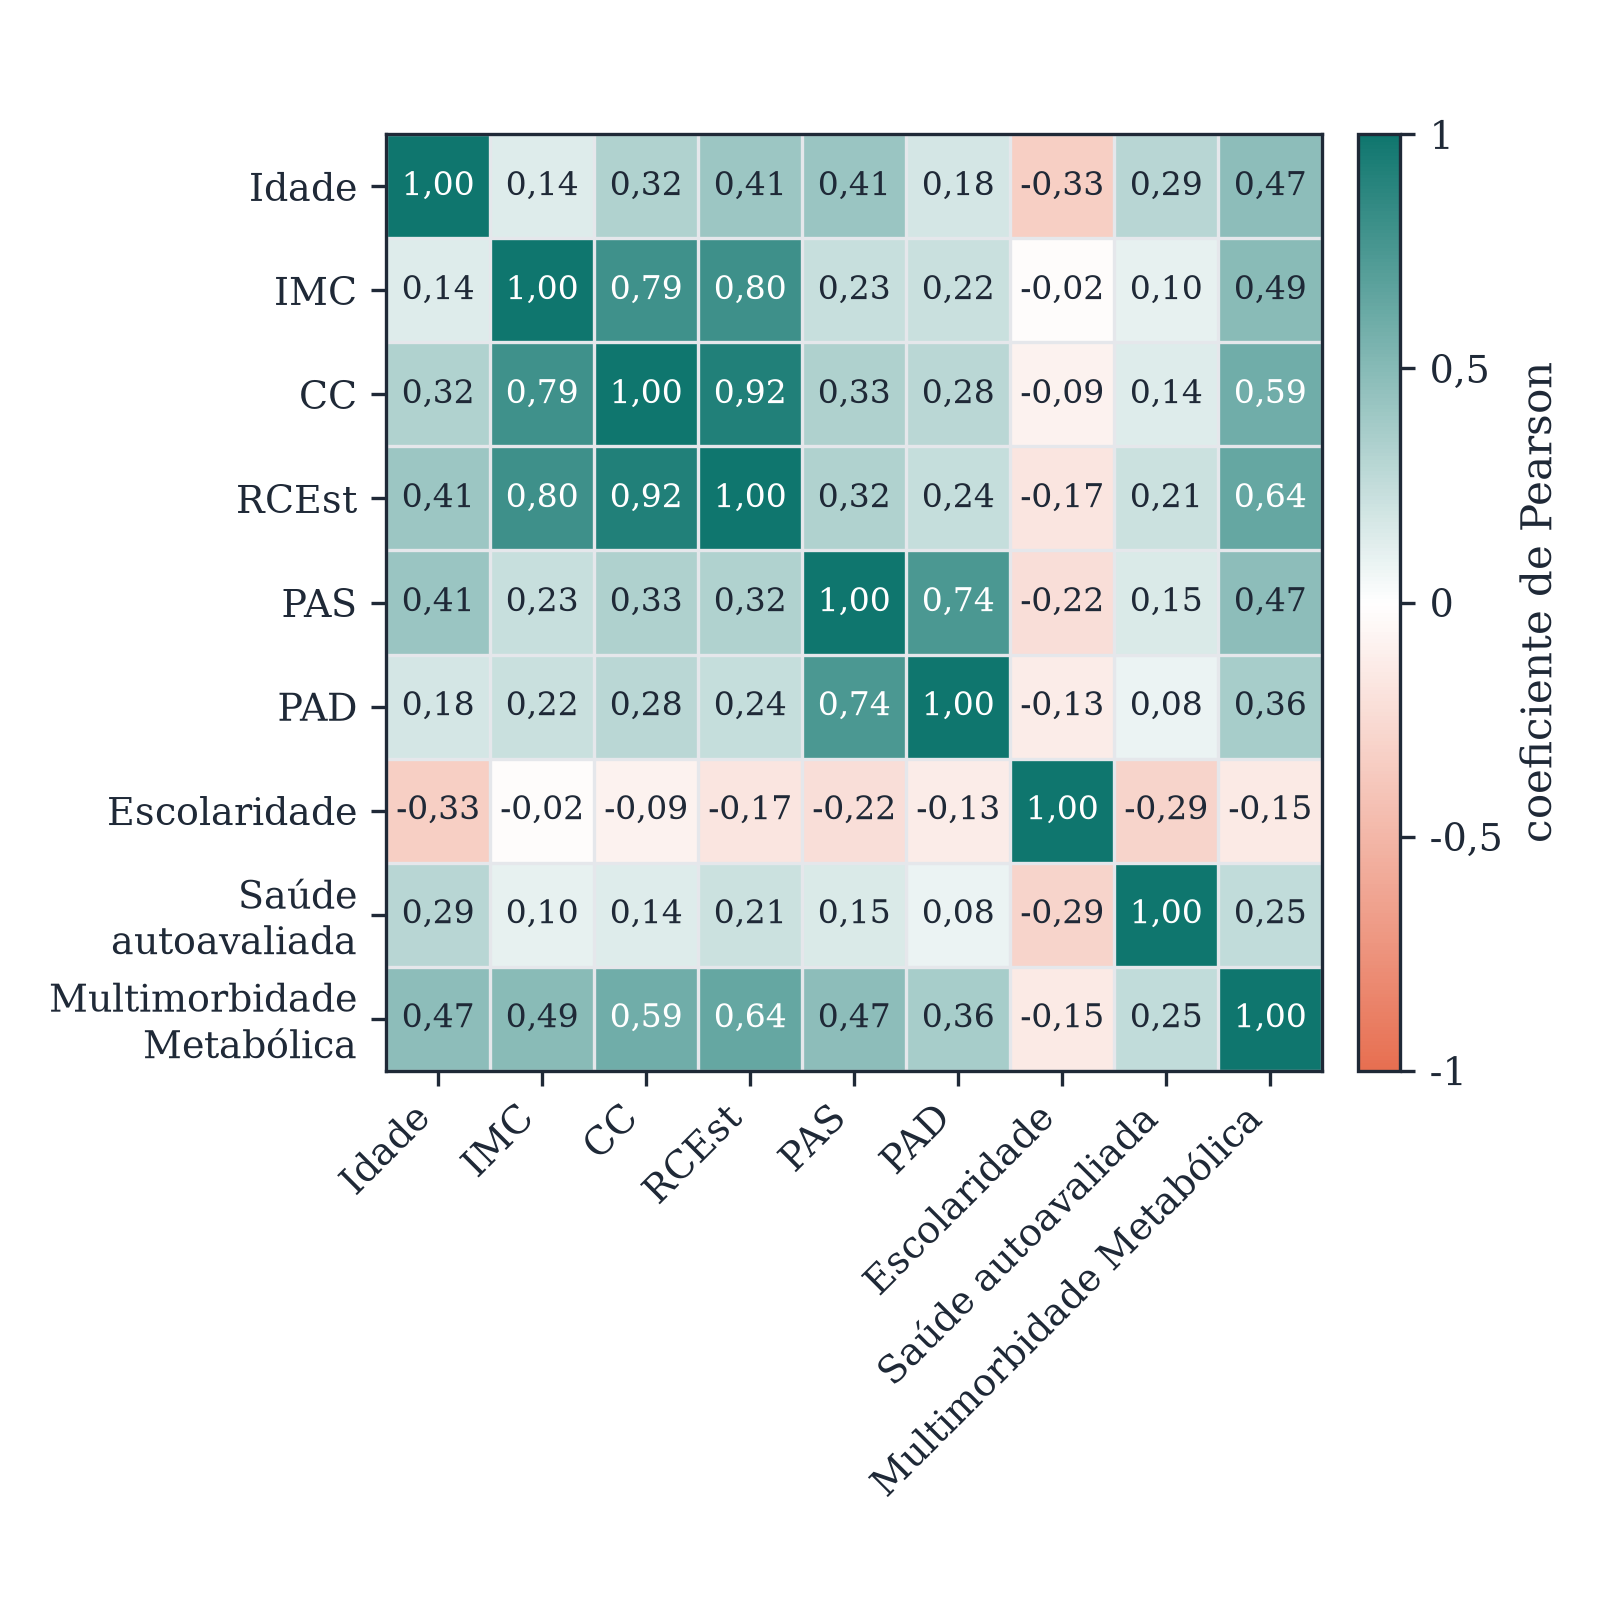

In [7]:
display(Image(filename=str(diag["figuras"]["C_completo"])))

O par `rcest` × `circ_cintura` tem Pearson 0,92, o que é esperado: a razão cintura-estatura é construída a partir da cintura. É a colinearidade que o protocolo manda tratar por remoção experimental.

In [8]:
pares = diag["pares_pearson"]
pares[pares["abs_pearson"] >= 0.5]

,feature_set,var_1,var_2,pearson,abs_pearson
0,A_atomico,imc,circ_cintura,0.792602,0.792602
1,A_atomico,pas,pad,0.742631,0.742631
21,B_composto,imc,circ_cintura,0.792602,0.792602
22,B_composto,circ_cintura,multimorbidade,0.587511,0.587511
36,C_completo,circ_cintura,rcest,0.916153,0.916153
37,C_completo,imc,rcest,0.799232,0.799232
38,C_completo,imc,circ_cintura,0.792602,0.792602
39,C_completo,pas,pad,0.742631,0.742631
40,C_completo,rcest,multimorbidade,0.636275,0.636275
41,C_completo,circ_cintura,multimorbidade,0.587511,0.587511


## Escolha do conjunto de atributos

Duas decisões se resolvem aqui, e **nenhuma das duas por desempenho**: ambas pela estrutura das variáveis.

**Primeira: `rcest` sai.** VIF 14,03 no conjunto completo; removida, `circ_cintura` cai de 13,73 para 4,70. Execução do protocolo de remoção experimental, não escolha ad hoc (D-019).

In [9]:
diag["ablacao_rcest"]

,variavel,vif_antes,r2_antes,acima_antes,vif_depois,r2_depois,acima_depois,delta_vif
0,circ_cintura,13.732556,0.927180,True,4.703812,0.787406,False,-9.028744
1,multimorbidade,8.604231,0.883778,False,8.604055,0.883776,False,-0.000176
2,has_combinada,6.028235,0.834114,False,6.027964,0.834107,False,-0.000271
3,imc,3.388618,0.704894,False,3.124849,0.679985,False,-0.263769
4,pas,3.040225,0.671077,False,3.039542,0.671003,False,-0.000684
5,has_autorrelato_3.0,2.848924,0.648990,False,2.848903,0.648988,False,-0.000021
6,colesterol_sim,2.520791,0.603299,False,2.520509,0.603255,False,-0.000282
7,pad,2.507037,0.601123,False,2.505722,0.600913,False,-0.001314
8,sexo_fem,2.277650,0.560951,False,1.581508,0.367692,False,-0.696142
9,idade,1.974118,0.493445,False,1.790797,0.441590,False,-0.183321


**Segunda: `C_completo` é descartado.** O escore de multimorbidade é, por construção, a soma de três parcelas binárias que também são colunas do modelo. Reconstruí-lo a partir delas dá R² = 1,000: identidade algébrica, não estimativa. A regressão auxiliar do VIF, que só enxerga `imc` e `circ_cintura` contínuas, chega a 0,884.

A distância entre os dois é a parcela da redundância que o diagnóstico linear **não enxerga**: o ponto de corte que binariza a obesidade não é recuperável por combinação linear. O argumento que descarta C é o princípio de ortogonalidade conceitual; a evidência é este par de R² (D-016).

In [10]:
decomposicao = diag["decomposicao_escore"]
print(f"R2 identidade (parcelas exatas): {decomposicao['r2_identidade']:.3f}")
print(f"R2 regressao auxiliar do VIF:    {decomposicao['r2_vif']:.3f}")
print(f"VIF de multimorbidade:           {decomposicao['vif']:.2f}")
print("Parcelas: " + ", ".join(decomposicao["parcelas"]))

R2 identidade (parcelas exatas): 1.000
R2 regressao auxiliar do VIF:    0.884
VIF de multimorbidade:           8.60
Parcelas: has_combinada, colesterol_sim, obesidade_reconstruida


Restam A e B. A decisão entre eles fica para depois da tabela de desempenho, onde se vê que **não é uma decisão de métrica**.

A floresta não roda em `C_completo`. O conjunto foi descartado, e publicar desempenho de conjunto descartado sugere que ele ainda está em disputa. A logística continua aparecendo nos três porque a linha de C é o lastro empírico do descarte: sem ela, a afirmação fica sem número para apontar (D-042).

## Desempenho: Regressão Logística e Random Forest

O grid roda aqui. O produto cartesiano não é cheio: a regra ADA e o Dummy não dependem do conjunto de atributos e são avaliados uma vez cada (D-028).

Os hiperparâmetros da floresta saíram de busca aleatória sobre o pipeline completo, no treino, com PR-AUC como métrica de seleção, e estão congelados como literais em `src/models.py`. O artefato da busca é `reports/tabelas/busca_rf.{tex,csv}` (D-033 a D-036).

Os dois modelos calibram o limiar no mesmo recall-alvo, cada um com o seu valor de limiar. Igualar o **número** do limiar entre modelos não significaria nada: a escala de probabilidade da floresta não é a da logística.

A chamada emite as tabelas em `reports/tabelas/`, salva as figuras do teste e confere o resultado contra as duas âncoras de reprodução.

In [11]:
saida = exp.executar(particao=particao, salvar_figuras=True)

calibraveis = [r for r in saida["resultados"] if r.get("limiar_calibrado", True)]
ev.comparar_formatado(calibraveis)

,modelo,conjunto,limiar,recall,especificidade,f1,auc_roc,nns
0,LogReg,A_atomico,0.424,0.748 (0.802 ± 0.027),0.627 (0.644 ± 0.015),0.224 (0.246 ± 0.010),0.775 (0.786 ± 0.015),7.58
1,LogReg,B_composto,0.445,0.765 (0.802 ± 0.008),0.637 (0.640 ± 0.023),0.233 (0.244 ± 0.011),0.781 (0.782 ± 0.013),7.26
2,LogReg,C_completo,0.419,0.756 (0.802 ± 0.026),0.625 (0.642 ± 0.015),0.226 (0.245 ± 0.007),0.770 (0.787 ± 0.014),7.54
3,Random Forest,A_atomico,0.320,0.782 (0.802 ± 0.024),0.632 (0.635 ± 0.017),0.235 (0.242 ± 0.011),0.786 (0.791 ± 0.016),7.22
4,Random Forest,B_composto,0.306,0.807 (0.802 ± 0.031),0.625 (0.624 ± 0.021),0.239 (0.236 ± 0.011),0.778 (0.788 ± 0.015),7.14


Formato `teste (CV: média ± dp)`. A dispersão entre folds não é enfeite: é a escala que diz se a diferença entre células significa alguma coisa.

**A e B seguem indistinguíveis.** Na logística, a vantagem de B sobre A em recall é 0,017 e o desvio entre folds do próprio A é 0,027. A diferença entre conjuntos é menor que a variação de partição dentro de um deles. O mesmo quadro reapareceu no espaço de hiperparâmetros: os vencedores de A e de B têm formatos bem diferentes e ficam separados por 0,0012 em PR-AUC. A escolha de `B_composto` se decide por parcimônia e interpretabilidade, 16 colunas contra 20, e é assim que ela deve ser apresentada à banca (D-021, D-036).

**A floresta supera a logística em recall no teste**, 0,807 contra 0,765 em `B_composto`, com diferença maior que a dispersão entre folds. A regra de decisão foi escrita antes de existir número, e o veredito é o que ela produziu (D-037). Duas ressalvas entram junto, e as duas estão nas seções seguintes: a PR-AUC da floresta é **menor** nos dois conjuntos, e a vantagem de `Random Forest · B_composto` é local ao ponto de operação, o que não vale para `Random Forest · A_atomico`.

Modelo de referencia (menor NNS entre os calibraveis): Random Forest / B_composto - NNS 7.14


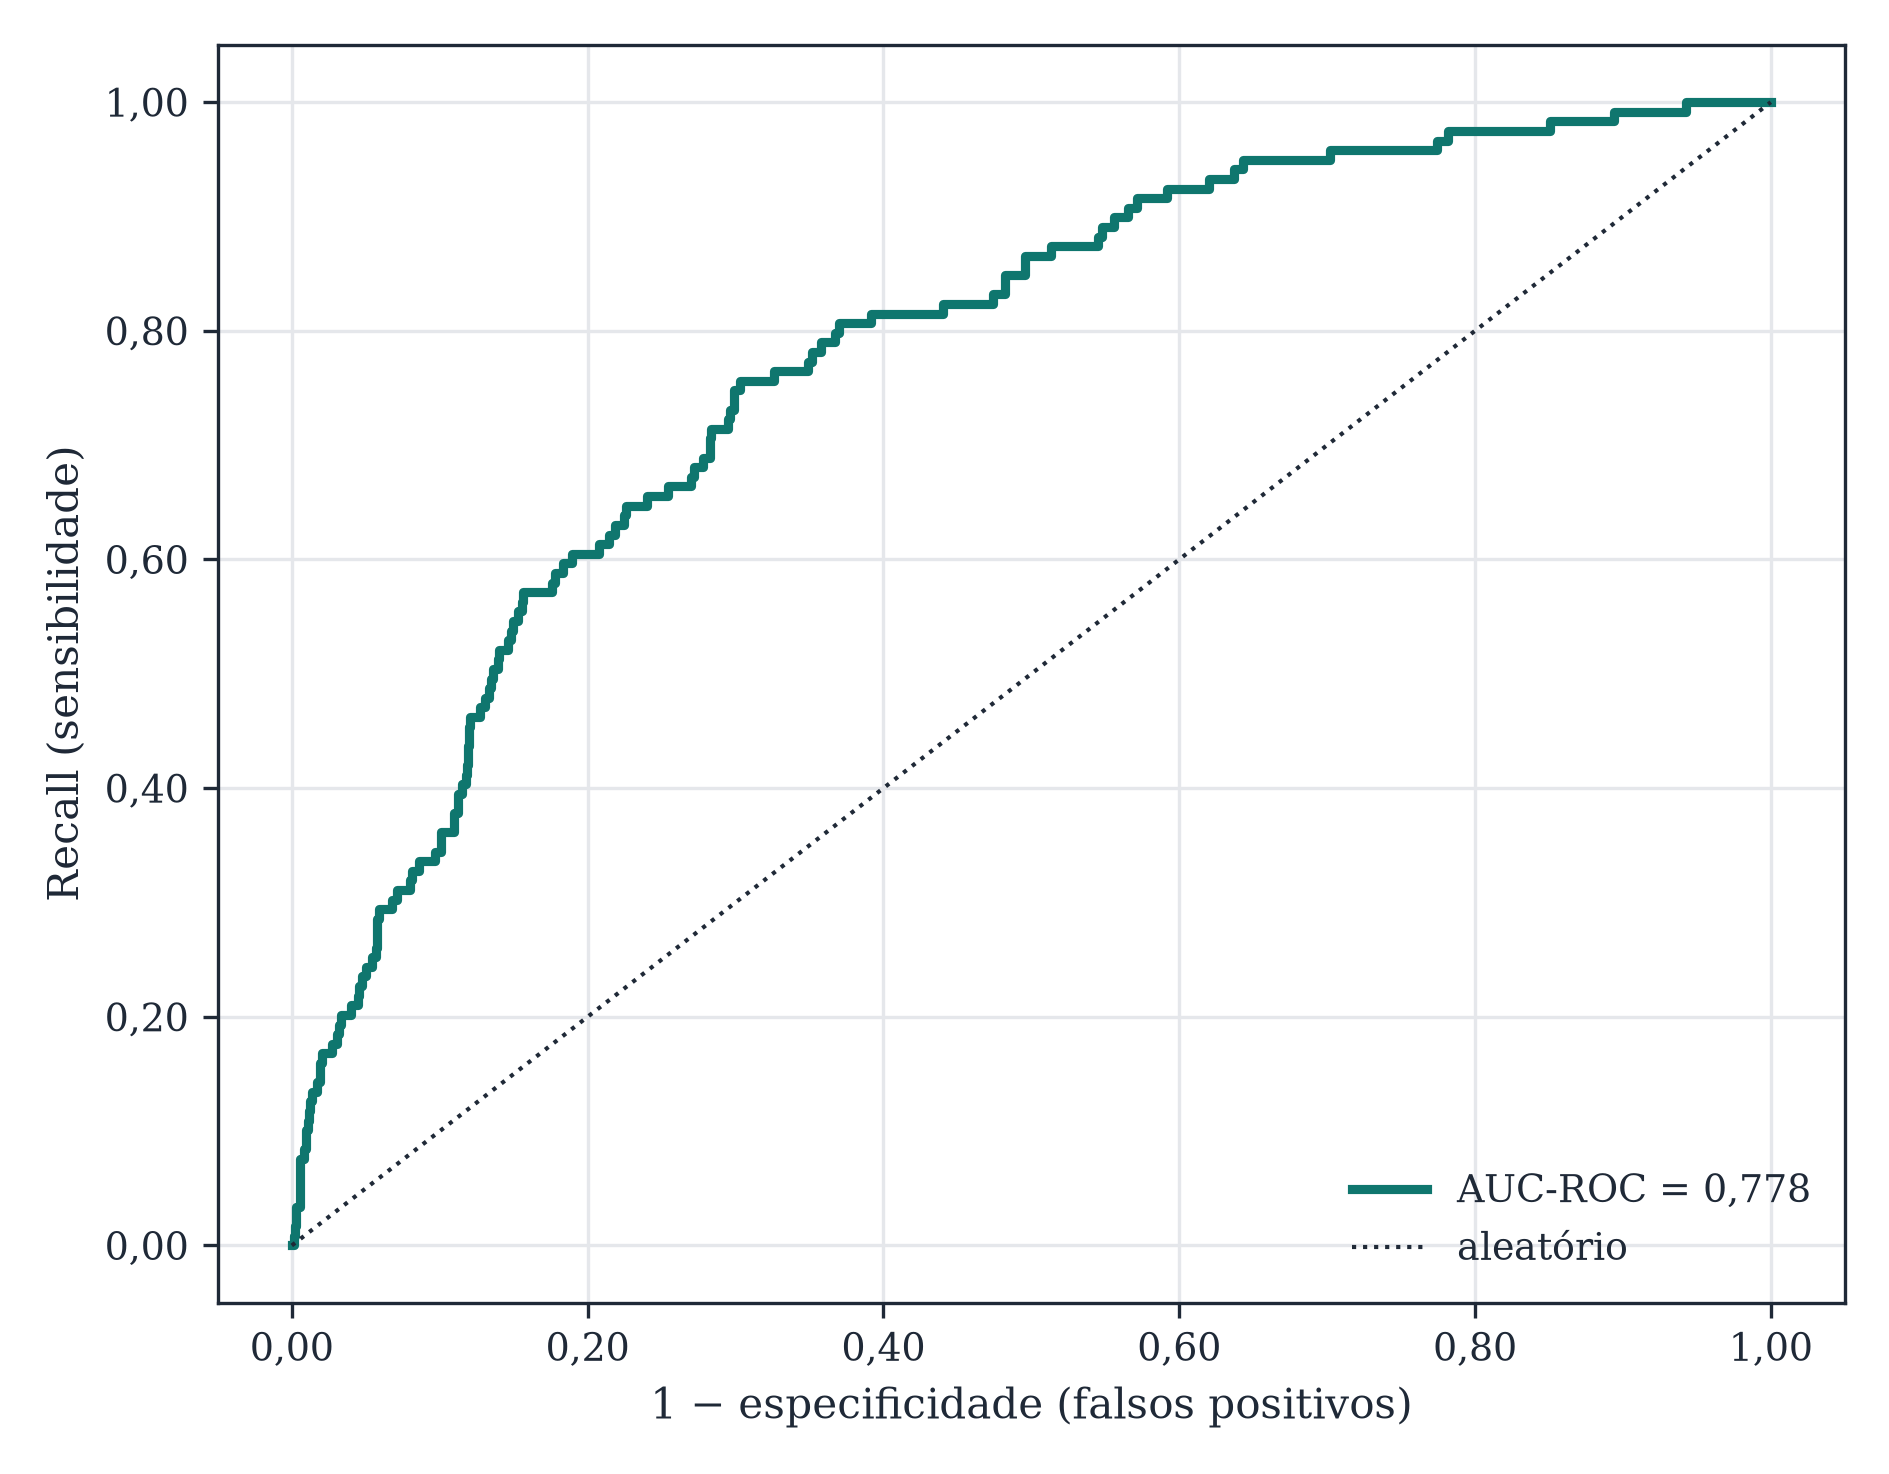

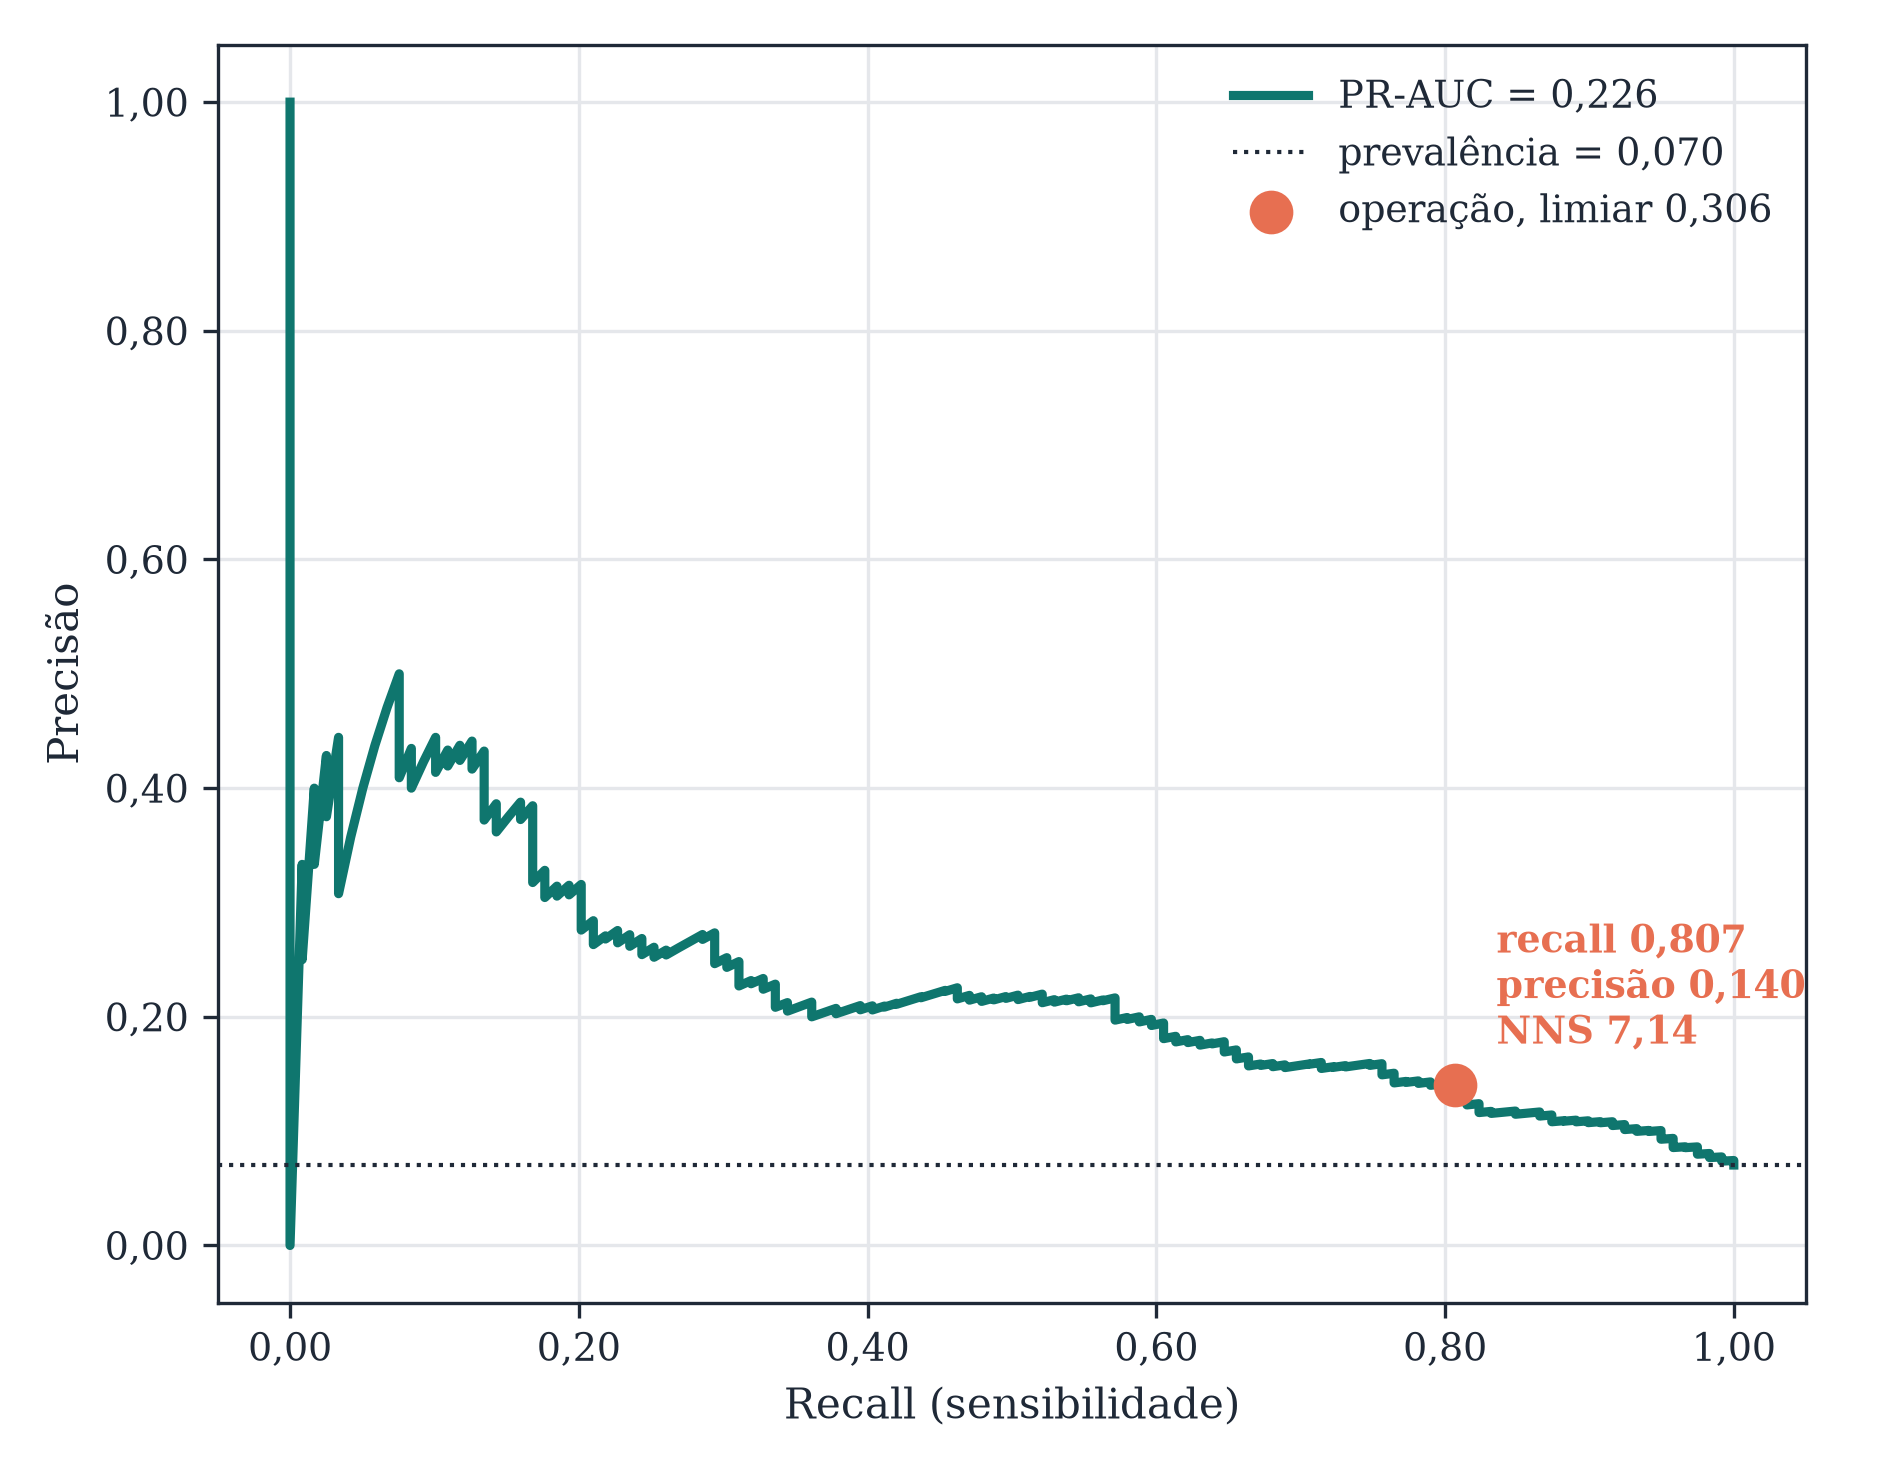

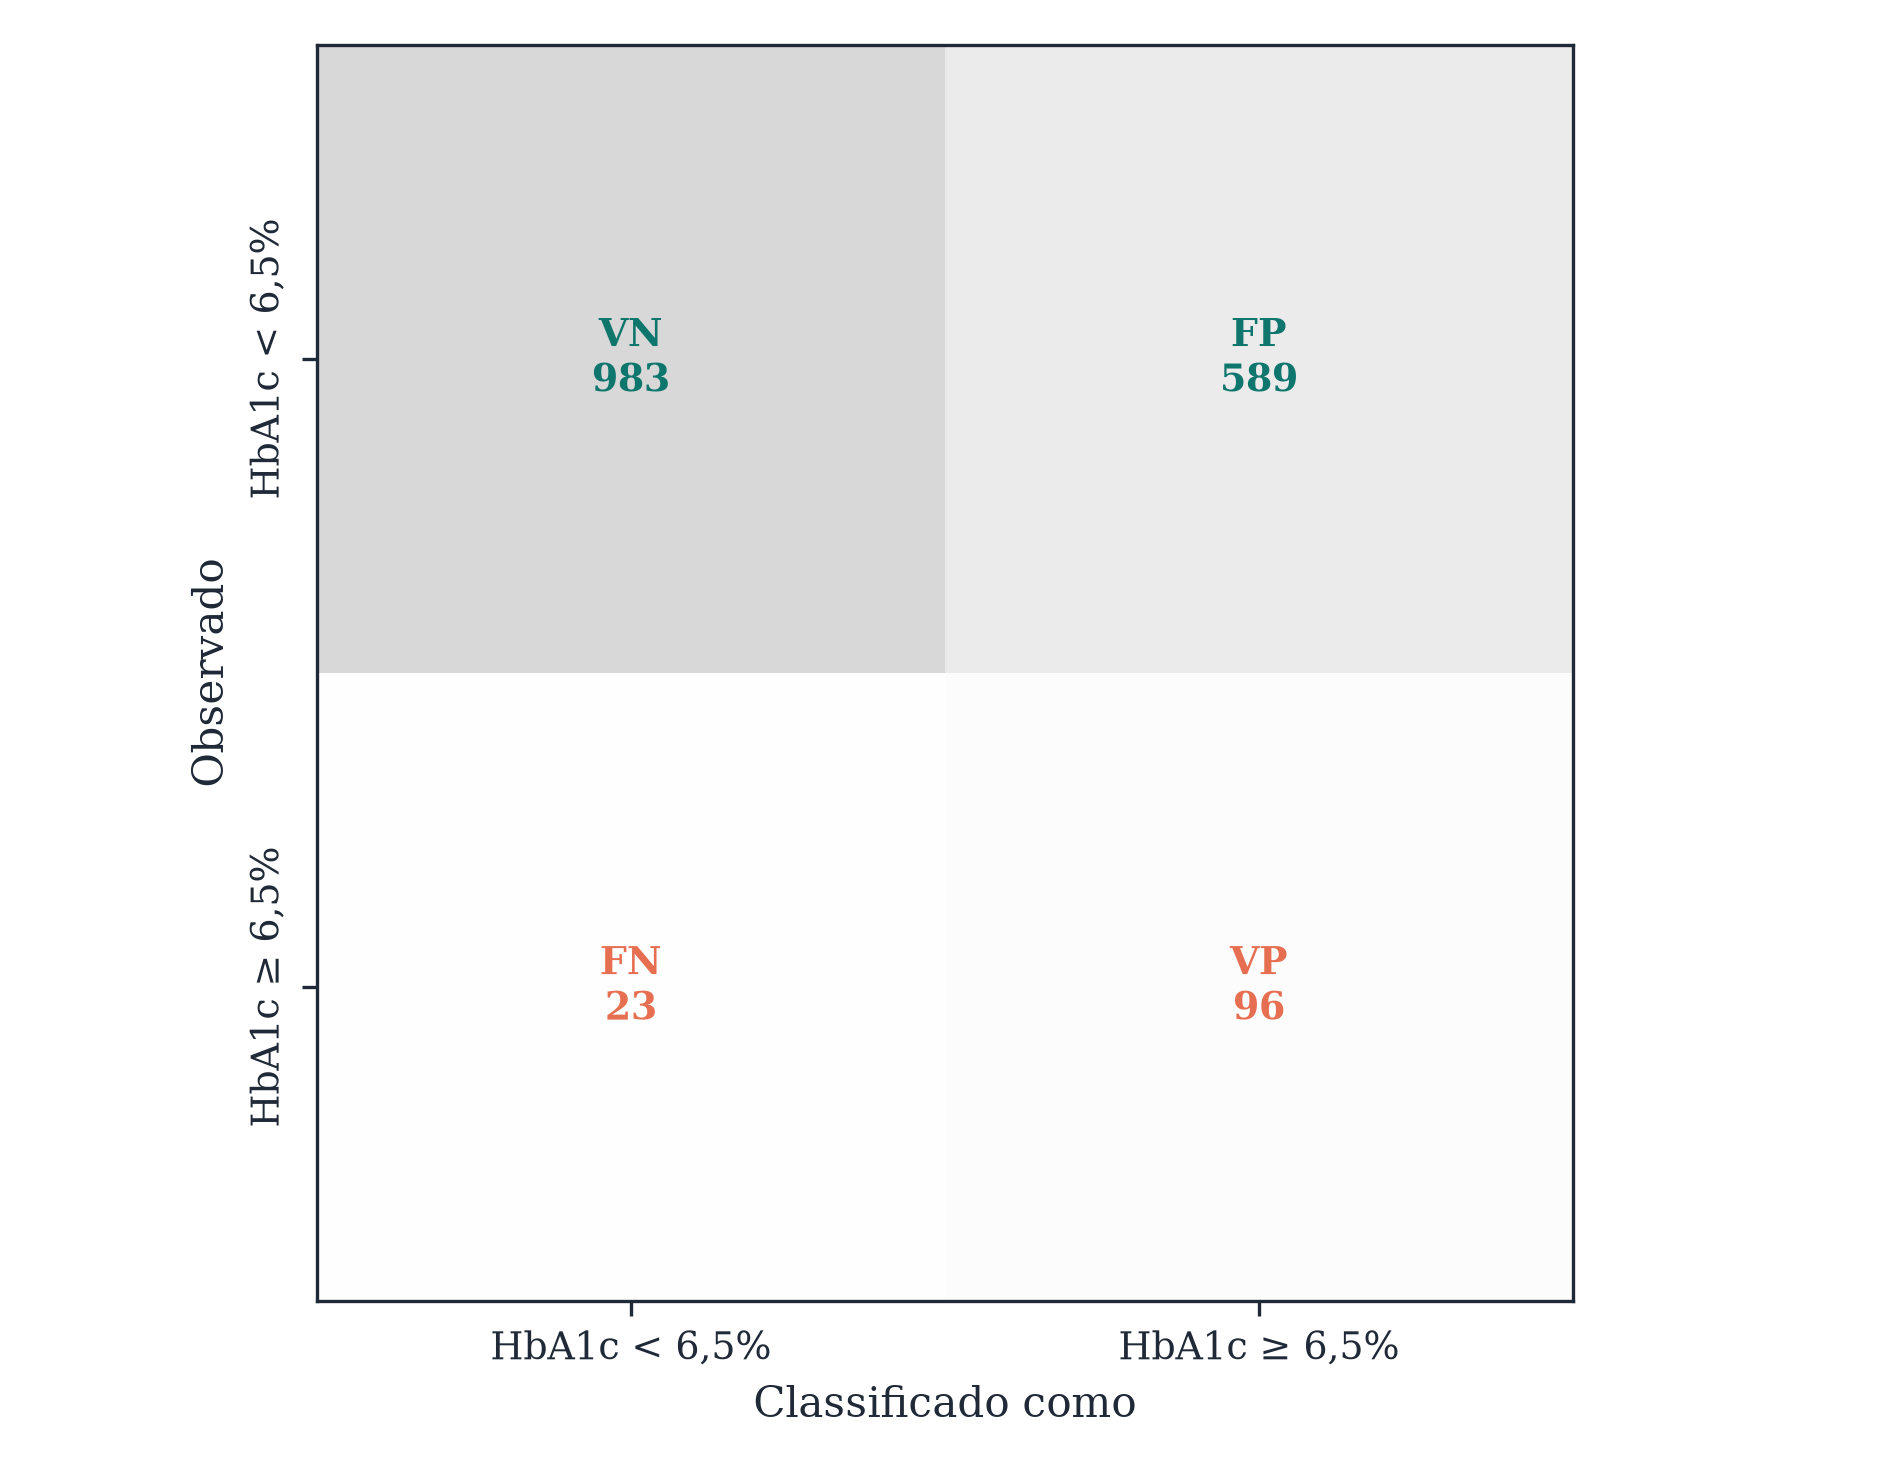

In [12]:
referencia = exp.modelo_de_referencia(saida["resultados"])
print(f"Modelo de referencia (menor NNS entre os calibraveis): "
      f"{referencia['modelo']} / {referencia['conjunto']} - NNS {referencia['nns']:.2f}")

for chave in ("roc", "precision_recall", "confusao"):
    display(Image(filename=str(referencia["figuras"][chave])))

## Teste pareado de McNemar

A comparação de recall diz que um número é maior que o outro. Ela não diz se os dois modelos acertam as **mesmas pessoas**, e a frase que se pode escrever muda conforme o caso: dois modelos podem diferir porque um detecta um superconjunto do outro ou porque cada um pega um subconjunto diferente.

O teste compara as duas células caso a caso, no teste, cada modelo no **seu** limiar calibrado. O p-valor sai do teste binomial exato sobre as discordâncias, sem aproximação assintótica, que é justamente onde ela vale menos com poucas dezenas de casos discordantes.

Acrescentado depois do veredito de D-037, e não o altera. O que ele muda é a linguagem do texto (D-043).

In [13]:
mcnemar = saida["mcnemar"]
mcnemar["tabela"]

,LogReg · B_composto acerta,LogReg · B_composto erra
Random Forest · B_composto acerta,1016,63
Random Forest · B_composto erra,77,535


In [14]:
print(ev.leitura_do_mcnemar(mcnemar))

Entre 1691 casos do teste, os dois modelos discordam em 140: 63 em que só Random Forest · B_composto acerta e 77 em que só LogReg · B_composto acerta. Pelo teste binomial exato, p = 0.2718, e a diferença de acerto global não é significativa ao nível de 0.05. No recorte que interessa à triagem, Random Forest · B_composto detecta um superconjunto estrito dos positivos que LogReg · B_composto pega: 5 a mais e nenhum no sentido inverso.


As duas leituras não se contradizem. A floresta acerta mais positivos e erra mais negativos, porque encaminha mais gente. O McNemar global soma os dois efeitos e eles quase se cancelam; o recorte nos positivos mostra o que a triagem compra.

A frase correta para o texto é **supera em recall, com diferença de acerto global não significativa, detectando um superconjunto dos casos**, e não "supera" sem qualificação. A qualificação não enfraquece o resultado, ela o descreve.

In [15]:
ev.tabela_mcnemar(mcnemar)

,modelo_a,modelo_b,n,concordam,so_a_acerta,so_b_acerta,positivos_so_a_detecta,positivos_so_b_detecta,p_valor,ambos_acertam,ambos_erram,discordancias,positivos_teste
0,Random Forest · B_composto,LogReg · B_composto,1691,1551,63,77,5,0,0.271842,1016,535,140,119


## Calibração

**As probabilidades não são risco individual, e cada modelo erra de um jeito.**

Na logística, o intercepto de calibração reproduz o logito da prevalência de treino em três casas. É o deslocamento algébrico previsível do `class_weight='balanced'`: reequilibrar as classes soma uma constante ao logito, e a constante é essa (D-022).

Na floresta a identidade **não se transfere**, e não poderia: floresta não tem intercepto, a saída é fração de votos. O intercepto medido fica em −2,06 e −2,13 contra o logito de −2,585, errando por 0,46. O deslocamento existe e é grande, mas não é o efeito previsível do reponderamento (D-040).

A floresta é menos descalibrada em todos os índices, com Brier 0,13 contra 0,19, ECE 0,24 contra 0,33 e inflação 4,4× contra 5,6×, e o slope fica mais perto de 1. Continua perdendo para um previsor constante na prevalência, por metade da margem.

O slope perto de 1 nos dois casos é o que importa na prática: a **ordenação** está preservada, e ordenação é tudo que a triagem precisa, porque a decisão é o limiar. A escala não é. Um escore de 0,60 não significa 60% de chance. É limitação a declarar nos resultados, não defeito a esconder.

In [16]:
ev.tabela_calibracao_comparada(saida["resultados"])

,modelo,conjunto,brier,brier_trivial,brier_skill,prevalencia,proba_media,razao_inflacao,ece,slope,intercepto
0,LogReg,A_atomico,0.192154,0.06542,-1.937225,0.070373,0.393509,5.591797,0.323137,0.879470,-2.573512
1,LogReg,B_composto,0.195942,0.06542,-1.995125,0.070373,0.398668,5.665111,0.328296,0.927904,-2.592296
2,LogReg,C_completo,0.192693,0.06542,-1.945467,0.070373,0.392640,5.579450,0.322268,0.841817,-2.563467
3,Random Forest,A_atomico,0.132898,0.06542,-1.031448,0.070373,0.305487,4.340998,0.235115,1.030976,-2.059180
4,Random Forest,B_composto,0.139321,0.06542,-1.129630,0.070373,0.310731,4.415514,0.240358,0.936920,-2.128817
5,Regra ADA,—,0.774690,0.06542,-10.841737,0.070373,0.840331,11.941176,0.774690,0.063981,-3.313714
6,Dummy (maioria),—,0.070373,0.06542,-0.075700,0.070373,0.000000,0.000000,0.070373,0.185850,-0.013452


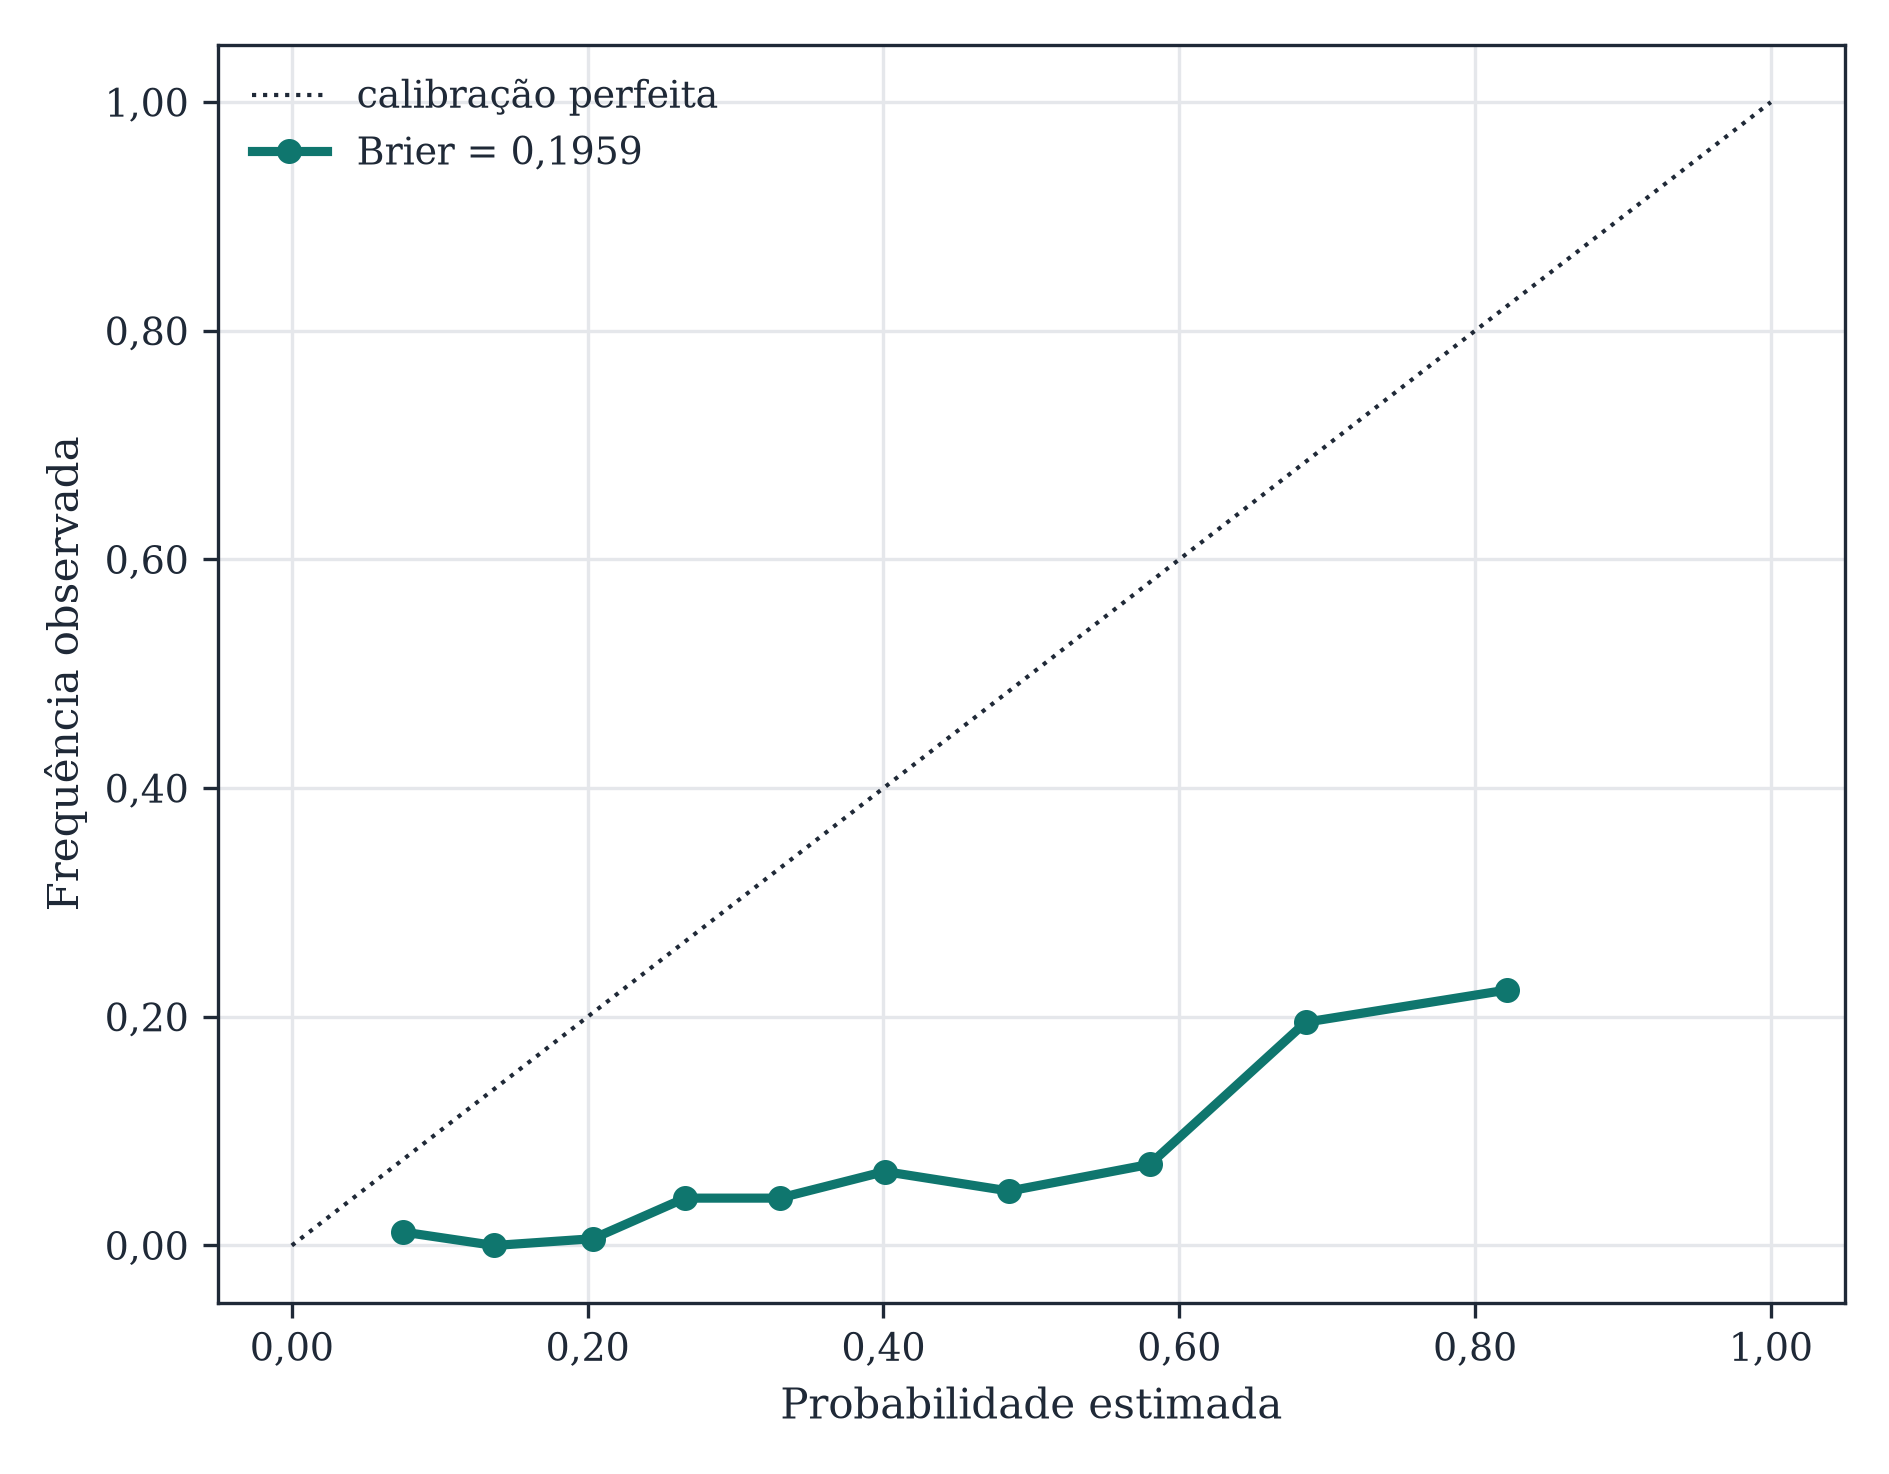

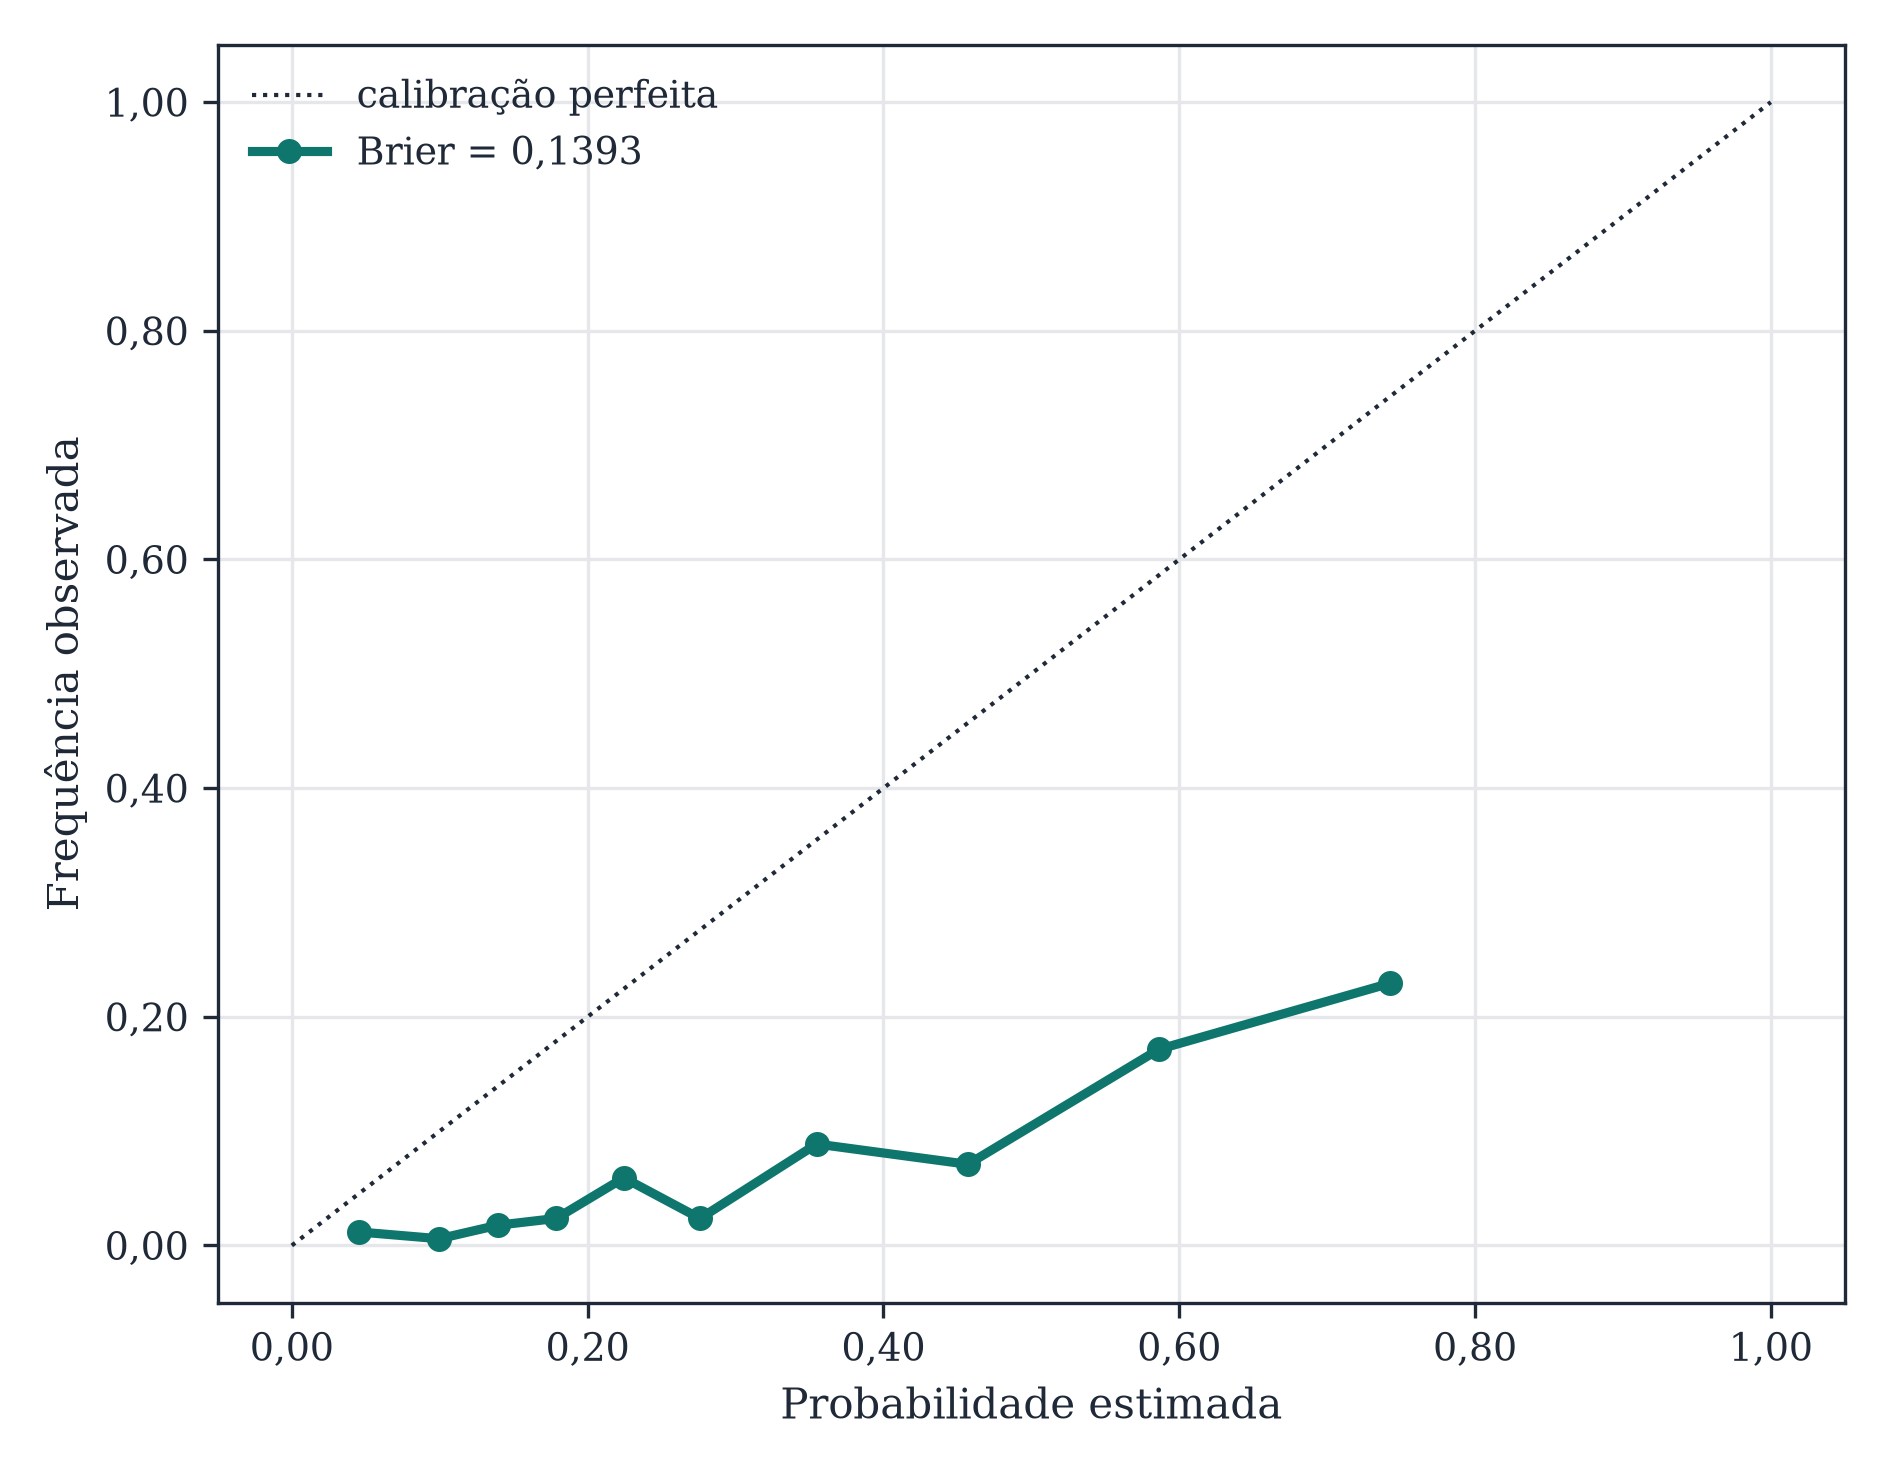

In [17]:
for nome in ("LogReg", exp.NOME_FLORESTA):
    celula = exp.celula(saida["resultados"], nome, "B_composto")
    display(Image(filename=str(celula["figuras"]["calibracao"])))

## Comparadores não-ML

Dois pisos. A **regra clínica ADA** (`idade ≥ 35 OU IMC ≥ 25`) é o comparador que importa: é o que a rede já faz hoje, com as mesmas variáveis não invasivas e nenhuma estimação. O **Dummy** existe para tornar visível o que a prevalência de 7% permite, acertar 93% das vezes sem classificar ninguém (D-006, D-023).

As sete linhas da tabela publicada: logística em três conjuntos, floresta em dois, mais um comparador invariante cada.

In [18]:
ev.comparar_formatado(saida["resultados"])

,modelo,conjunto,limiar,recall,especificidade,f1,auc_roc,nns
0,LogReg,A_atomico,0.424,0.748 (0.802 ± 0.027),0.627 (0.644 ± 0.015),0.224 (0.246 ± 0.010),0.775 (0.786 ± 0.015),7.58
1,LogReg,B_composto,0.445,0.765 (0.802 ± 0.008),0.637 (0.640 ± 0.023),0.233 (0.244 ± 0.011),0.781 (0.782 ± 0.013),7.26
2,LogReg,C_completo,0.419,0.756 (0.802 ± 0.026),0.625 (0.642 ± 0.015),0.226 (0.245 ± 0.007),0.770 (0.787 ± 0.014),7.54
3,Random Forest,A_atomico,0.320,0.782 (0.802 ± 0.024),0.632 (0.635 ± 0.017),0.235 (0.242 ± 0.011),0.786 (0.791 ± 0.016),7.22
4,Random Forest,B_composto,0.306,0.807 (0.802 ± 0.031),0.625 (0.624 ± 0.021),0.239 (0.236 ± 0.011),0.778 (0.788 ± 0.015),7.14
5,Regra ADA,—,0.500,0.966 (0.977 ± 0.014),0.169 (0.184 ± 0.003),0.149 (0.153 ± 0.002),0.568 (0.581 ± 0.006),12.36
6,Dummy (maioria),—,0.500,0.000 (0.000 ± 0.000),1.000 (1.000 ± 0.000),0.000 (0.000 ± 0.000),0.500 (0.500 ± 0.000),inf


In [19]:
print(ev.nota_corte_unico(saida["consolidado"]))

Nota: Dummy (maioria), Regra ADA são classificadores de corte único — a saída assume dois valores, não um escore. AUC-ROC, PR-AUC, Brier e a curva de calibração dependem de percorrer limiares e, para essas linhas, ficam degradadas por construção, não por desempenho. As métricas comparáveis entre todas as linhas são Recall, Especificidade e NNS.


Aplicado o critério de sucesso ao ponto de operação padrão (mais recall **com** NNS menor, conjuntivamente), nenhum modelo domina a regra. Isso diz mais sobre os pontos de operação do que sobre os classificadores: o modelo está calibrado em recall-alvo 0,80 e a regra opera em 0,966. Comparação entre estratégias em recalls diferentes não é comparação. É o que a próxima seção resolve (D-024).

In [20]:
bm.supera_a_regra_clinica(saida["resultados"])

,estrategia,recall_alvo,recall_obtido,recall_regra,delta_recall,nns,nns_regra,delta_nns,supera
0,LogReg · A_atomico,0.8,0.747899,0.966387,-0.218487,7.584270,12.356522,-4.772252,False
1,LogReg · B_composto,0.8,0.764706,0.966387,-0.201681,7.263736,12.356522,-5.092785,False
2,LogReg · C_completo,0.8,0.756303,0.966387,-0.210084,7.544444,12.356522,-4.812077,False
3,Random Forest · A_atomico,0.8,0.781513,0.966387,-0.184874,7.215054,12.356522,-5.141468,False
4,Random Forest · B_composto,0.8,0.806723,0.966387,-0.159664,7.135417,12.356522,-5.221105,False
5,Dummy (maioria),NaN,0.000000,0.966387,-0.966387,inf,12.356522,inf,False


## Carga operacional

Os três regimes de encaminhamento. É o resultado que sustenta a conclusão do trabalho, e é onde ela fica condicionada.

O regime equiparado recalibra o modelo de referência no recall que a regra obtém **no treino**. Medi-lo no teste vazaria o teste para dentro da decisão de limiar (R1, R2). É o cálculo que mais atravessa treino e teste de propósito, e por isso o que mais precisa estar versionado.

In [21]:
saida["carga"]

,regime,encaminhados,taxa_encaminhamento,casos_detectados,casos_perdidos,recall,nns,regime_id,rotulo
0,Regra ADA,1421,0.840331,115,4,0.966387,12.356522,regra,Regra ADA
1,"Random Forest · B_composto, recall equiparado ...",1461,0.863986,117,2,0.983193,12.487179,equiparado,"Random Forest · B_composto, recall equiparado ..."
2,"Random Forest · B_composto, ponto padrão (reca...",685,0.405086,96,23,0.806723,7.135417,padrao,"Random Forest · B_composto, ponto padrão (reca..."


In [22]:
print(saida["carga"].attrs["leitura"])

Regra ADA encaminha 1421 de 1691 pessoas (84.0%) para detectar 115 casos. Random Forest · B_composto encaminha 685 (40.5%) para detectar 96. Regra ADA encaminha mais da metade da população adulta, o que não seleciona quem examinar: apenas desloca a fila para o laboratório. No regime de recall equiparado, Random Forest · B_composto encaminha 40 pessoas a mais (1461 contra 1421) e detecta 2 casos a mais (117 contra 115), mas com NNS superior, ou seja, pior (12.49 contra 12.36): a comparação válida é por NNS, não por volume absoluto, já que os recalls realizados diferem (0.983 contra 0.966).


**Cuidado de leitura.** No regime equiparado o modelo encaminha *mais* gente que a regra em números absolutos. Lida isoladamente, a tabela sugere desvantagem. A resposta está no recall realizado, que é maior, e é o que o NNS já incorpora por normalizar pelos casos detectados. Volume absoluto só é comparável entre estratégias que operam no mesmo recall.

A advertência acompanha a tabela em `attrs["nota"]`, para que ela não circule sem.

In [23]:
print(saida["carga"].attrs["nota"])

Volume de encaminhamentos só é comparável entre estratégias que operam no mesmo recall. Quando os recalls realizados diferem, a comparação é por NNS, que normaliza por casos detectados — no regime de recall equiparado um modelo pode encaminhar mais pessoas que a regra em números absolutos e ainda assim ter NNS menor, por detectar mais casos.


### O critério de sucesso no regime equiparado, e de quem ele fala

Dito em voz alta, porque resultado negativo é resultado e a banca vai perguntar.

O critério é superar a regra em recall **com NNS menor**, e as duas condições valem juntas. No regime equiparado quem **não cumpre** é a célula de referência, `Random Forest · B_composto`: NNS 12,487 contra 12,357 da regra. O veredito abaixo vale para ela, e só para ela, porque a carga operacional equipara o modelo de referência e mais ninguém.

A leitura larga, de que a floresta não cumpre o critério, não se sustenta no artefato: das cinco células calibráveis, **uma cumpre** no regime equiparado, a floresta em `A_atomico`, com NNS 12,347. A tabela célula a célula vem logo adiante (D-046, D-047).

In [24]:
saida["carga"].attrs["criterio"]

,regime,recall,recall_regra,delta_recall,nns,nns_regra,delta_nns,cumpre
0,"Random Forest · B_composto, recall equiparado ...",0.983193,0.966387,0.016807,12.487179,12.356522,0.130658,False
1,"Random Forest · B_composto, ponto padrão (reca...",0.806723,0.966387,-0.159664,7.135417,12.356522,-5.221105,False


In [25]:
print(exp.leitura_do_criterio(saida["carga"]))

Random Forest · B_composto, recall equiparado (alvo 0.9768 no treino): NÃO cumpre o critério, recall 0.983 contra 0.966 da regra e NNS 12.49 contra 12.36 (Δ recall +0.017, Δ NNS +0.13).
Random Forest · B_composto, ponto padrão (recall-alvo 0.80): NÃO cumpre o critério, recall 0.807 contra 0.966 da regra e NNS 7.14 contra 12.36 (Δ recall -0.160, Δ NNS -5.22).
Random Forest · B_composto não cumpre o critério em nenhum regime avaliado aqui. O veredito vale para esta célula: as demais estão em equiparado_por_modelo.
Nota: Random Forest · B_composto, ponto padrão (recall-alvo 0.80) opera em recall abaixo do da regra. O critério pede recall maior com NNS menor ao mesmo tempo, e NNS medido em recalls diferentes não decide nada. Aí a comparação registra o resultado, não o critério. Quem decide é o regime de recall equiparado, onde os dois lados miram o mesmo recall.


### O regime equiparado de todas as células calibráveis

`carga_operacional` equipara o modelo de referência e mais ninguém. `equiparado_por_modelo` cobre o grid inteiro, e é dele que sai a tabela célula a célula (D-047).

`recall_alvo` é onde a equiparação acontece, no treino. `recall_obtido` é o que se realizou no teste, e ele desvia do alvo porque o limiar é fixado fora da amostra de avaliação. O que está equiparado é o regime de operação, não o resultado, e a comparação é por NNS (D-047).

In [26]:
saida["equiparado"]

,estrategia,modelo,conjunto,recall_alvo,recall_obtido,recall_regra,encaminhados,casos_detectados,nns,cumpre_criterio,taxa_encaminhamento
0,Regra ADA,Regra ADA,—,NaN,0.966387,0.966387,1421,115,12.356522,<NA>,0.840331
1,LogReg · A_atomico,LogReg,A_atomico,0.976793,0.983193,0.966387,1480,117,12.649573,False,0.875222
2,LogReg · B_composto,LogReg,B_composto,0.976793,0.983193,0.966387,1470,117,12.564103,False,0.869308
3,LogReg · C_completo,LogReg,C_completo,0.976793,0.983193,0.966387,1449,117,12.384615,False,0.856889
4,Random Forest · A_atomico,Random Forest,A_atomico,0.976793,0.991597,0.966387,1457,118,12.347458,True,0.861620
5,Random Forest · B_composto,Random Forest,B_composto,0.976793,0.983193,0.966387,1461,117,12.487179,False,0.863986


**O mecanismo está na margem.** No regime equiparado, floresta e logística em `B_composto` realizam o mesmo recall, 0,983, e detectam os mesmos 117 casos. A floresta encaminha 9 pessoas a menos, 1.461 contra 1.470. `custo_marginal_pareado` lê dominância da floresta nesse par. O NNS da floresta fica em 12,487 e o da logística em 12,564. Os dois ficam acima do NNS da regra, 12,357.

**E a leitura fecha com o resto da evidência.** A PR-AUC da floresta é menor nos dois conjuntos, 0,2255 contra 0,2441 em `B_composto`, e PR-AUC é a métrica que mede a ordenação ao longo de toda a curva sob prevalência baixa. A AUC-ROC empata, melhor em A e pior em B, com diferença na terceira casa. A ordenação global, portanto, é **pior**.

**A inversão de NNS entre floresta e logística não aparece.** No ponto padrão a floresta tem NNS 7,135417 em `B_composto` e a logística 7,263736. No equiparado, 12,487179 e 12,564103. A floresta fica à frente nos dois regimes. O que o equiparado muda é o critério contra a regra: em `B_composto` nenhuma das duas células o cumpre.

Em `A_atomico` a floresta também atravessa os dois regimes à frente da logística. As quatro células, com o NNS do ponto padrão vindo de `comparativo_consolidado.csv` e o do equiparado de `equiparado_por_modelo.csv`:

| Célula | NNS ponto padrão | NNS equiparado |
|---|---|---|
| LogReg · `A_atomico` | 7,584270 | 12,649573 |
| Random Forest · `A_atomico` | **7,215054** | **12,347458** |
| LogReg · `B_composto` | 7,263736 | 12,564103 |
| Random Forest · `B_composto` | **7,135417** | **12,487179** |

O que a tabela mostra é a floresta à frente da logística nos dois conjuntos e nos dois regimes. O que ela não toca é a evidência de ordenação global, que segue valendo nos dois conjuntos.

O TCC I escolheu a Random Forest pela capacidade de capturar interações não lineares. Se o ganho viesse daí, a ordenação global melhoraria. Ela piorou.

**Consequência.** Modelo principal e ponto de operação principal deixaram de ser decisões independentes. No regime equiparado uma das cinco células calibráveis cumpre o critério, `Random Forest · A_atomico`. As outras quatro não cumprem, e entre elas está a de referência, `Random Forest · B_composto`. Escolher o regime passou a escolher a célula junto, e as duas perguntas vão ao orientador como uma só (D-004, D-024, D-046).

A vantagem do modelo sobre a regra não é fazer o mesmo um pouco melhor: é **poder escolher o ponto de operação** conforme a capacidade instalada da rede, o que uma regra de corte único por definição não permite. A troca é explícita e quantificada, e a tabela acima a mostra nos dois sentidos.

## Conferência de reprodução e artefatos

Duas âncoras. `comparativo_logreg.tex` vem da primeira sprint e cobre as três linhas da logística; `comparativo_rf.tex` cobre as duas da floresta. A antiga ganhou função nova ao lado da que já tinha: ela agora prova que acrescentar a floresta ao grid **não moveu nenhum número da logística**. Se mover, é defeito no grid, não resultado (D-039).

A conferência exige coincidência até a terceira casa. Tabela vazia significa reprodução exata no escopo coberto.

In [27]:
saida["divergencias"]

,linha,coluna,referencia,obtido


Conferir valor não basta. A conferência de reprodução compara a interseção dos índices, então ela flagra número errado numa linha existente e deixa passar linha que sumiu: uma tabela truncada tem todos os números certos e o conteúdo errado, e foi assim que a consolidada sobreviveu com duas linhas e a suíte verde. A conferência de composição fecha isso, nomeando a célula ausente ou inesperada (D-044).

In [28]:
saida["composicao"]

,linha,situacao


In [29]:
for nome, caminhos in saida["artefatos"].items():
    print(f"{nome}: {' / '.join(p.name for p in caminhos.values())}")

comparativo_consolidado: comparativo_consolidado.tex / comparativo_consolidado.csv
carga_operacional: carga_operacional.tex / carga_operacional.csv
equiparado_por_modelo: equiparado_por_modelo.tex / equiparado_por_modelo.csv
calibracao_comparada: calibracao_comparada.tex / calibracao_comparada.csv
resumo_amostra: resumo_amostra.tex / resumo_amostra.csv
ausentes_por_variavel: ausentes_por_variavel.tex / ausentes_por_variavel.csv
mcnemar_pareado: mcnemar_pareado.tex / mcnemar_pareado.csv
custo_marginal_pareado: custo_marginal_pareado.tex / custo_marginal_pareado.csv
curva_roc: curva_roc.csv
curva_pr: curva_pr.csv
calibracao_decis: calibracao_decis.csv


## Explicabilidade via SHAP

**O que o SHAP mede.** Quanto cada variável move o escore *deste* modelo, para *este* indivíduo, a partir de um valor de base. A decomposição é aditiva: a soma das contribuições mais o valor de base reconstrói o escore, e a conferência dessa identidade é o que diz que a atribuição descreve o modelo e não outra coisa.

**O que ele não mede.** Efeito causal, o que aconteceria com alguém se a variável mudasse, e risco. A restrição de uso de D-022 e D-040 vale aqui inteira e fica agravada: as probabilidades da floresta não são risco individual, então a soma das contribuições reconstrói o escore do indivíduo e nunca o risco dele. O desenho continua transversal, e o que as atribuições descrevem são associações dentro do modelo ajustado.

A escala é fração de votos da classe positiva, que é a escala em que o limiar calibrado opera. O valor de base fica perto de 0,5 por efeito do reponderamento de classes, não na prevalência de 7% (D-053).

**Dois regimes de perturbação, e nenhum é opcional.** O principal é `tree_path_dependent` sobre as 500 árvores, e é ele que sustenta o SHAP global publicado. O de contraste é `interventional`, a formulação que assume independência entre variáveis, que é a que a referência aponta como frágil. A divergência entre os dois rankings é a medida da exposição deste trabalho ao problema, e sai como artefato em vez de afirmação em prosa (D-053).

O documento recalcula o regime principal, que é barato e entrega a atribuição linha a linha que as figuras consomem, e lê do `.csv` versionado o contraste, que é a parte cara. É a mesma relação que o notebook já tem com `busca_rf.csv`.

In [30]:
material = {celula: ex.material_das_figuras(celula, particao) for celula in ex.CELULAS}

for celula, medida in material.items():
    print(f"{celula}: limiar {medida['limiar']:.6f} conferido contra o publicado, "
          f"aditividade do regime principal {medida['erro_principal']:.2e}")

A_atomico: limiar 0.319963 conferido contra o publicado, aditividade do regime principal 5.55e-15
B_composto: limiar 0.305502 conferido contra o publicado, aditividade do regime principal 5.33e-15


### Atribuição global

Um ponto por indivíduo do teste, em cada variável conceitual, com a cor trazendo o valor observado. O ranking sozinho diz qual variável pesa; o enxame diz em que direção e com que dispersão.

A atribuição por coluna da matriz de design está em `shap_global_coluna`. Aqui as colunas de uma mesma nominal aparecem somadas, e a categoria de referência de cada uma tem atribuição zero por construção, efeito do `drop="first"`, não por irrelevância (D-053).

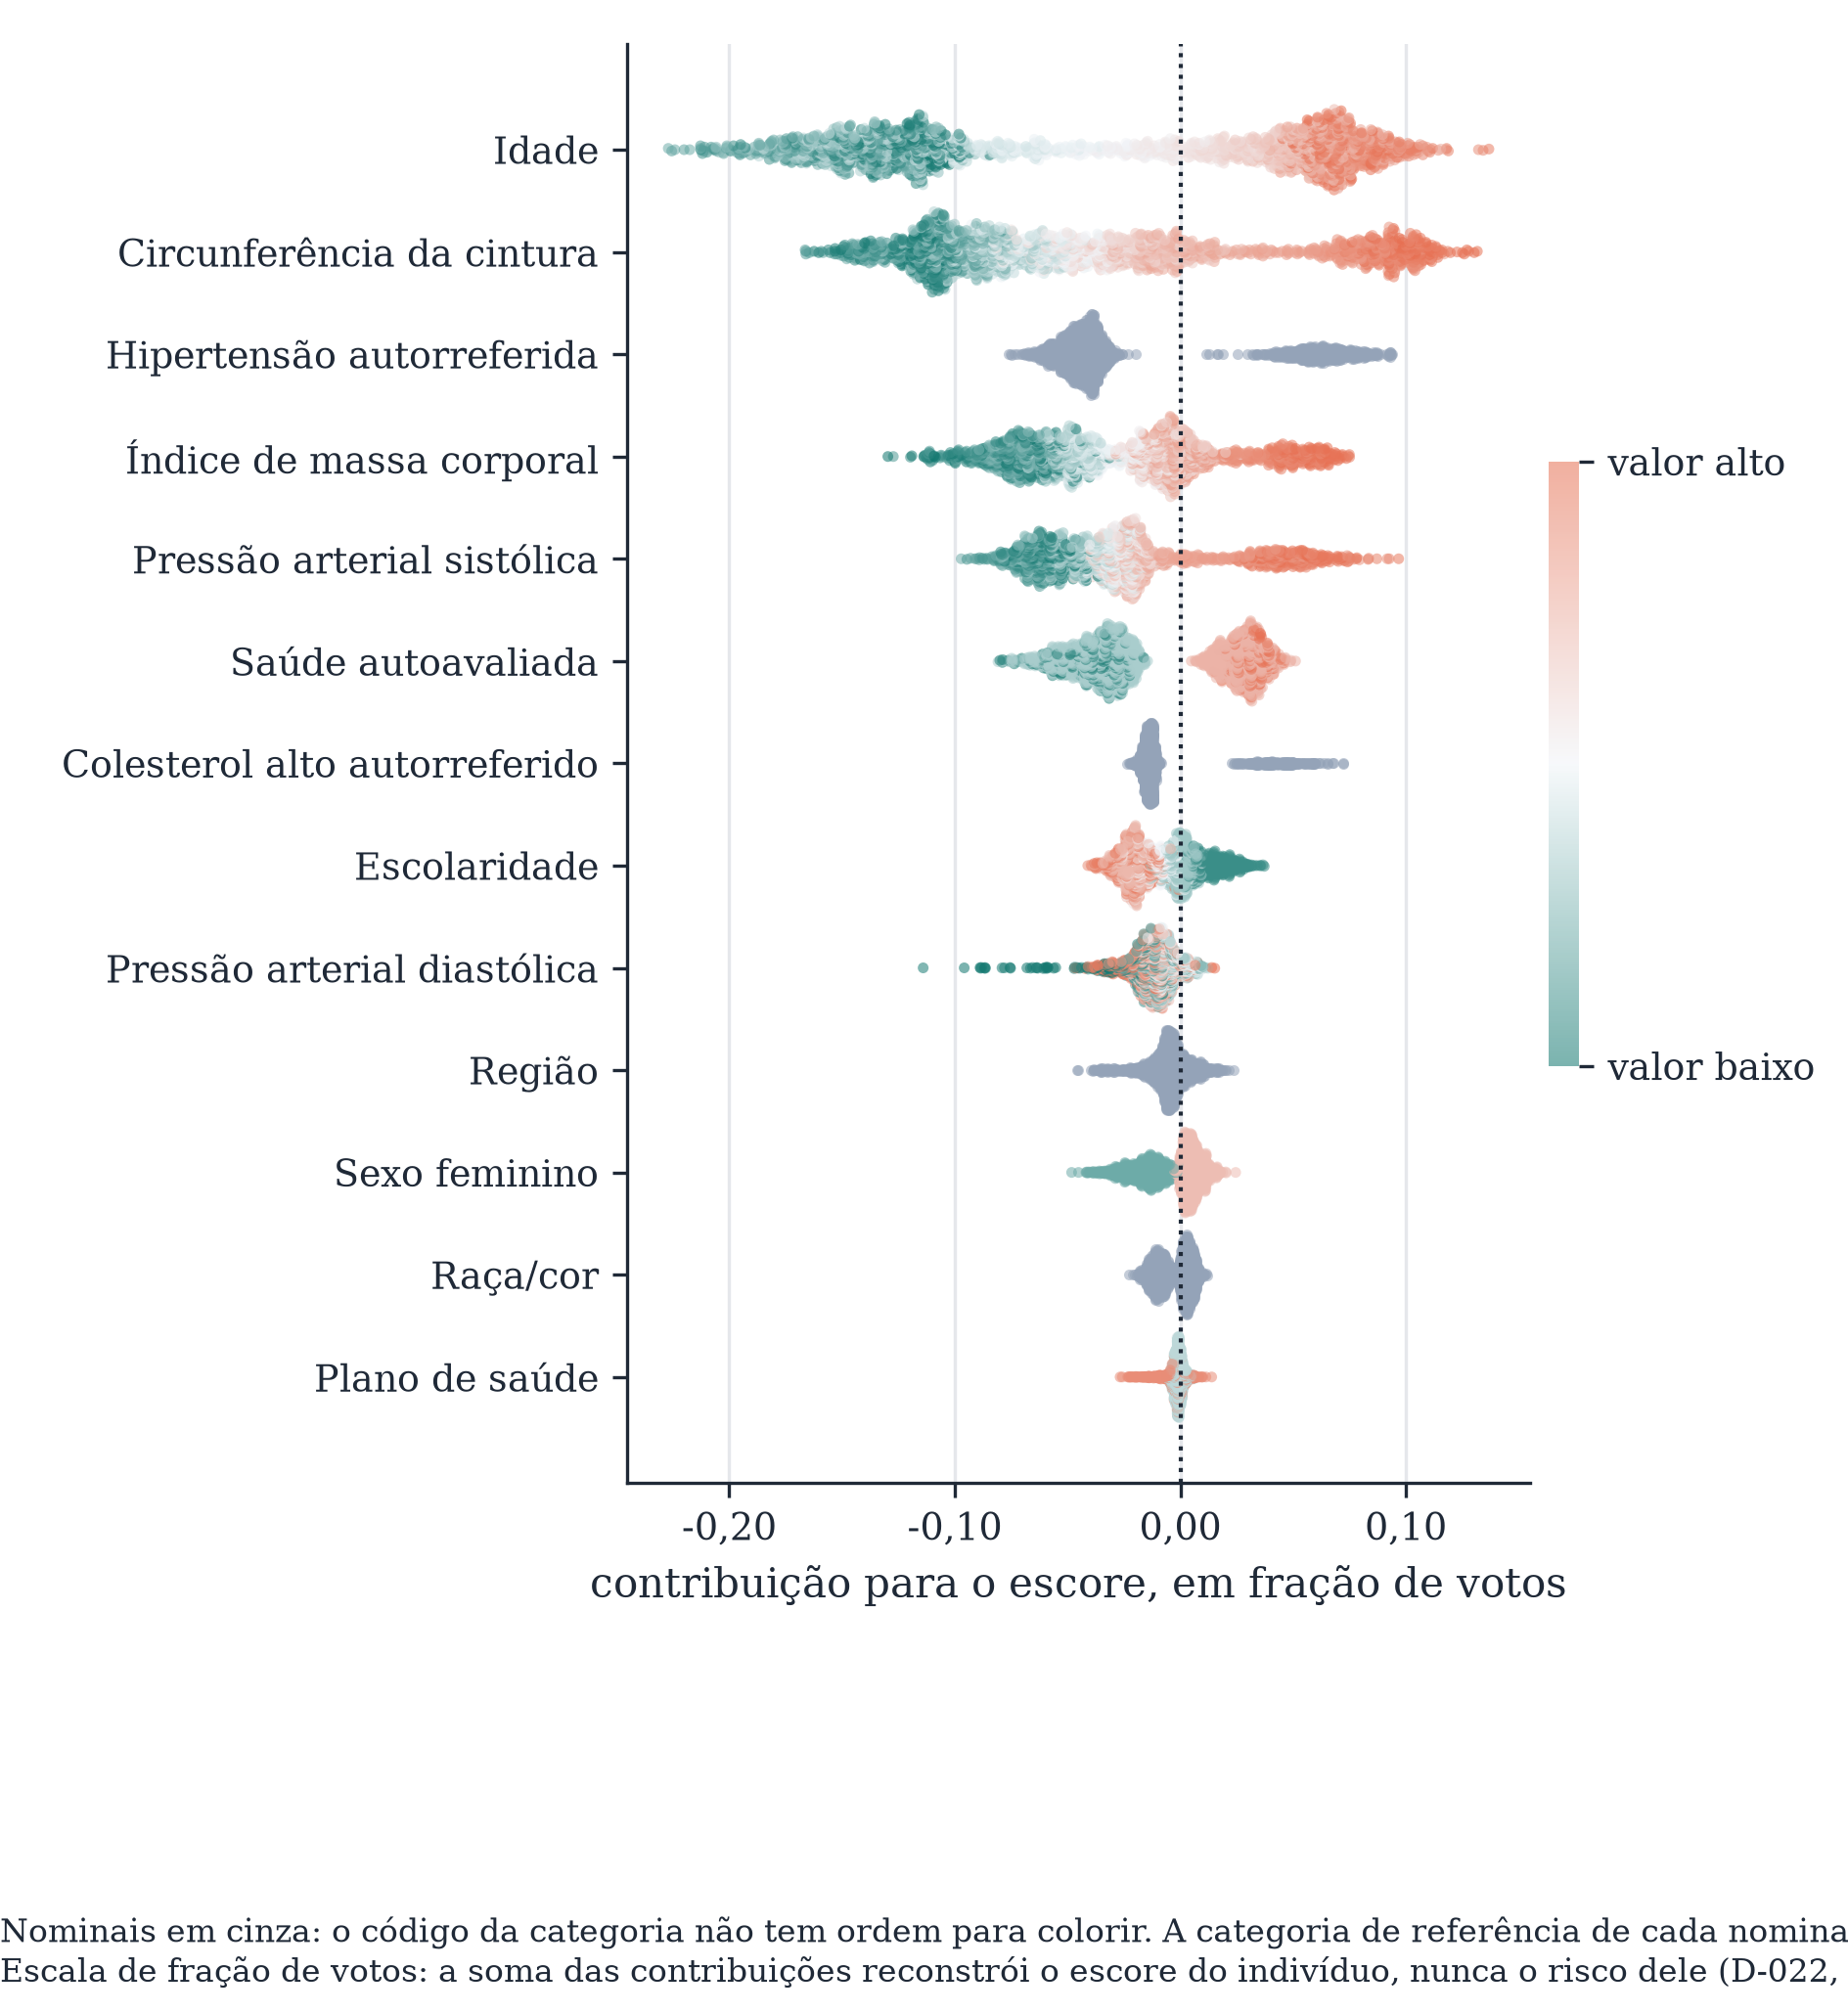

In [31]:
display(Image(filename=str(ex.figura_beeswarm(material["A_atomico"]))))

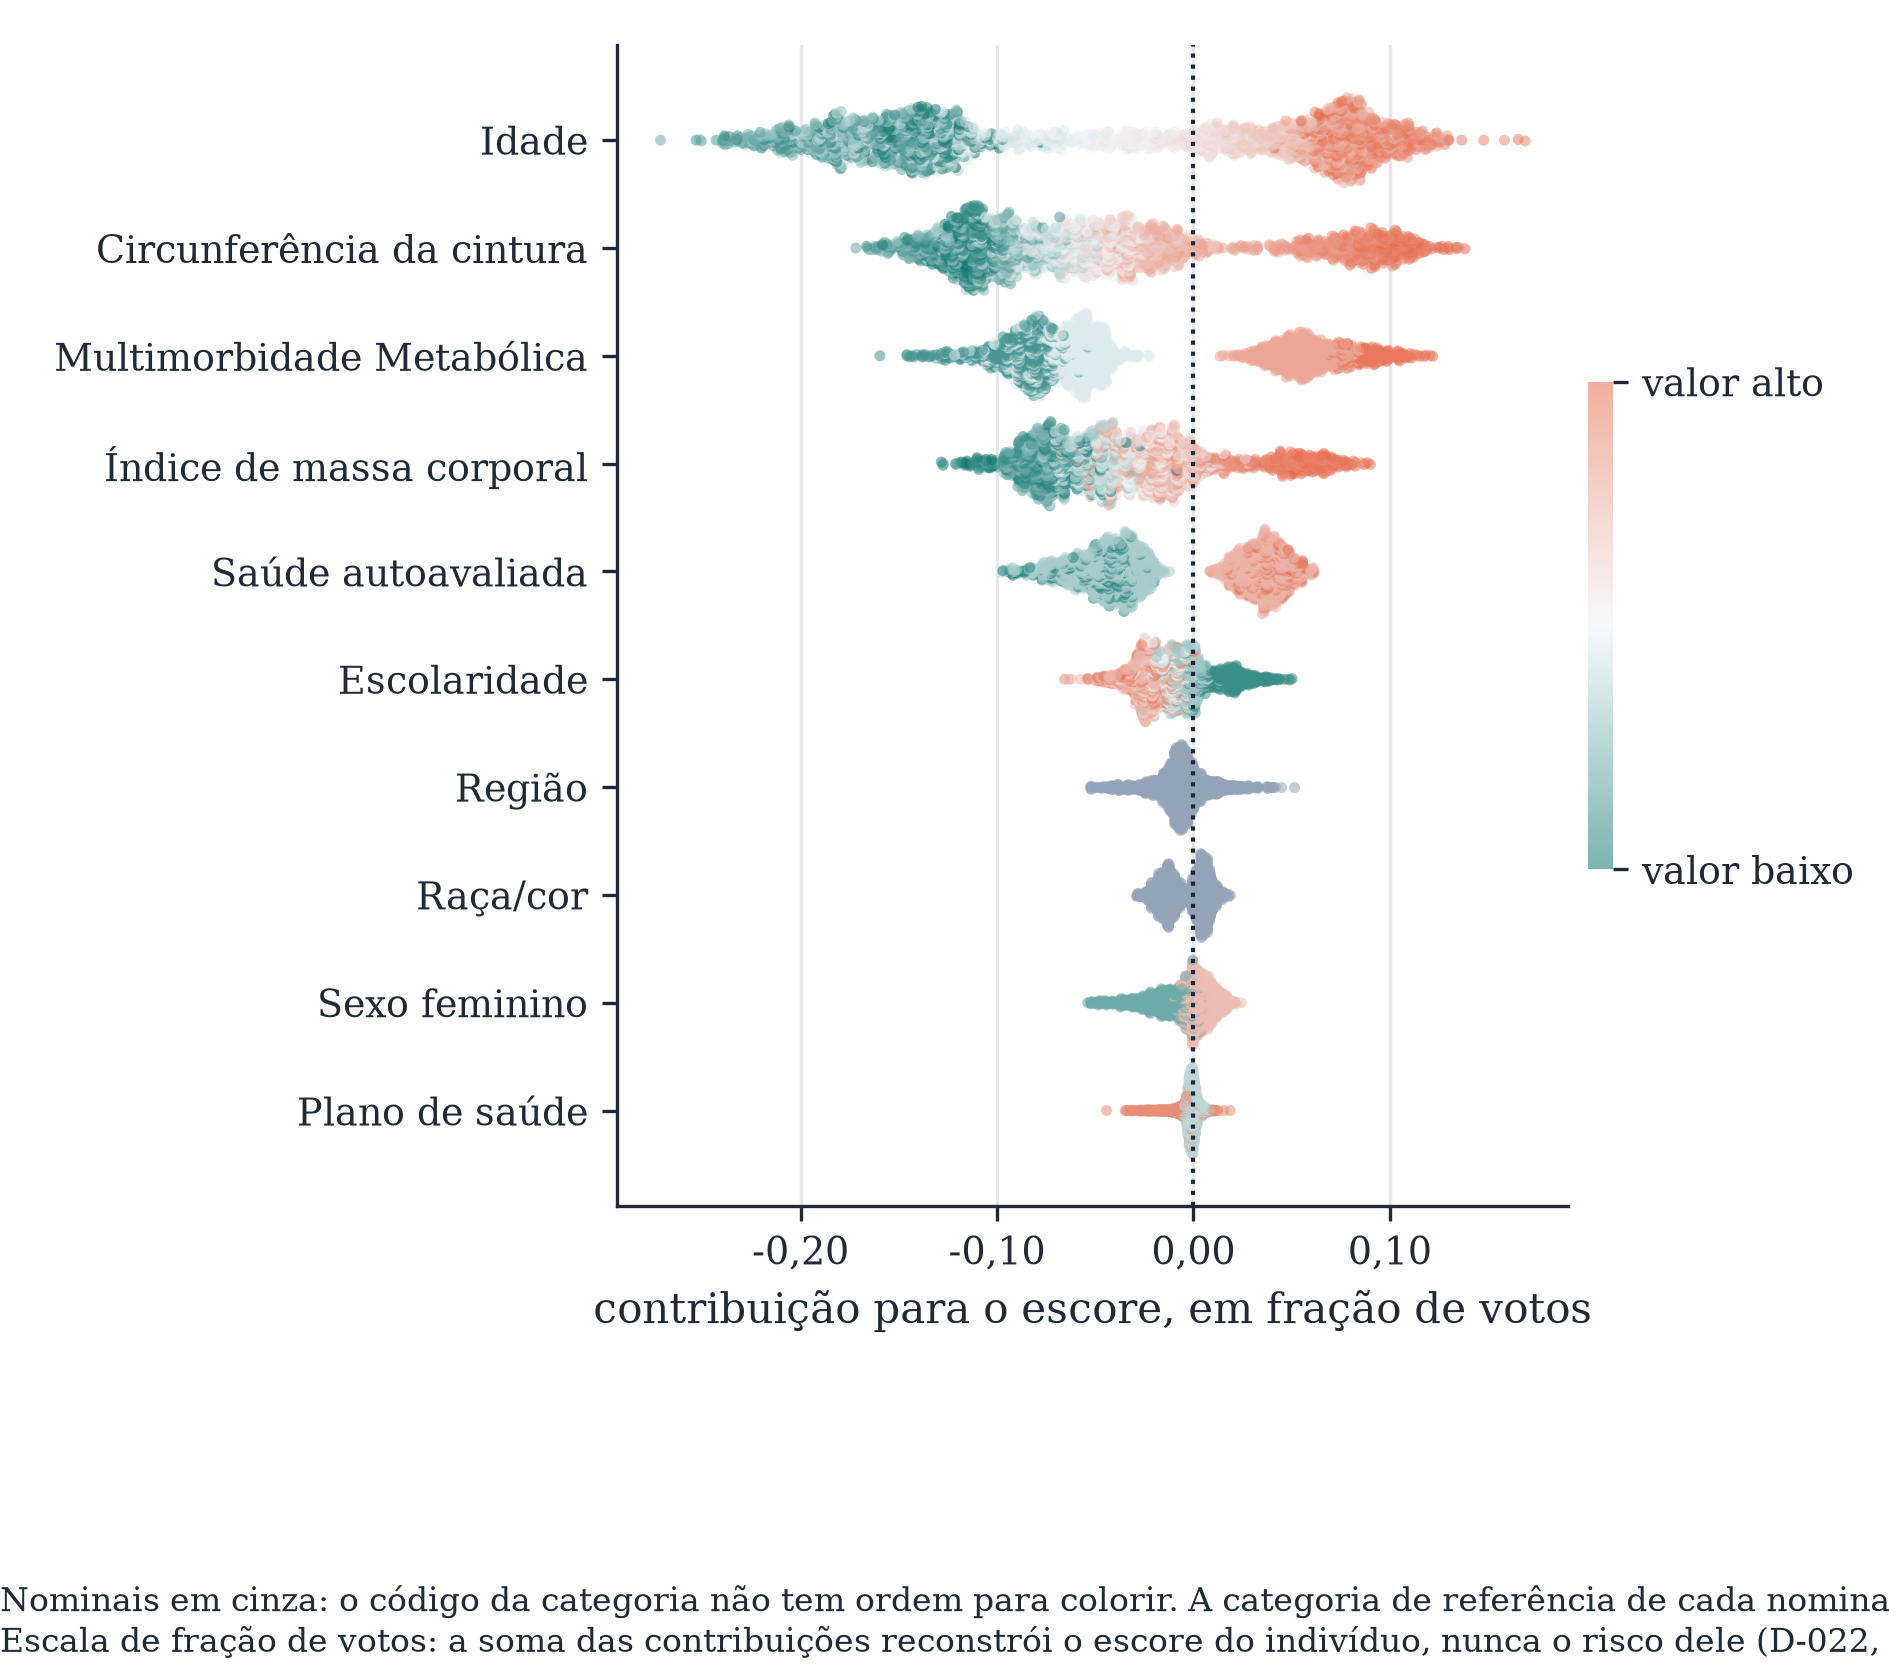

In [32]:
display(Image(filename=str(ex.figura_beeswarm(material["B_composto"]))))

### O contraste entre regimes

É a resposta à remissão que o texto assinado faz sobre mitigação da multicolinearidade, e o artefato é `shap_global_atributo`, lido aqui em vez de recalculado.

Em `A_atomico` as sete primeiras posições são idênticas nos dois regimes, e em `B_composto` as cinco primeiras. Toda a movimentação acontece na cauda, entre variáveis separadas por milésimos. A remoção das árvores não participa disso: `idade` vale 0,092460 na floresta completa e 0,092947 na reduzida. A suposição de independência não ameaça a leitura principal deste trabalho (D-053).

A queda de 15% a 25% no valor absoluto de todas as atribuições sob o regime de contraste tem leitura precisa: a soma com sinal é idêntica nos dois regimes, por aditividade sobre a mesma saída. O que cai é a média do módulo, ou seja, o regime principal produz atribuições maiores que se cancelam mais entre variáveis dependentes.

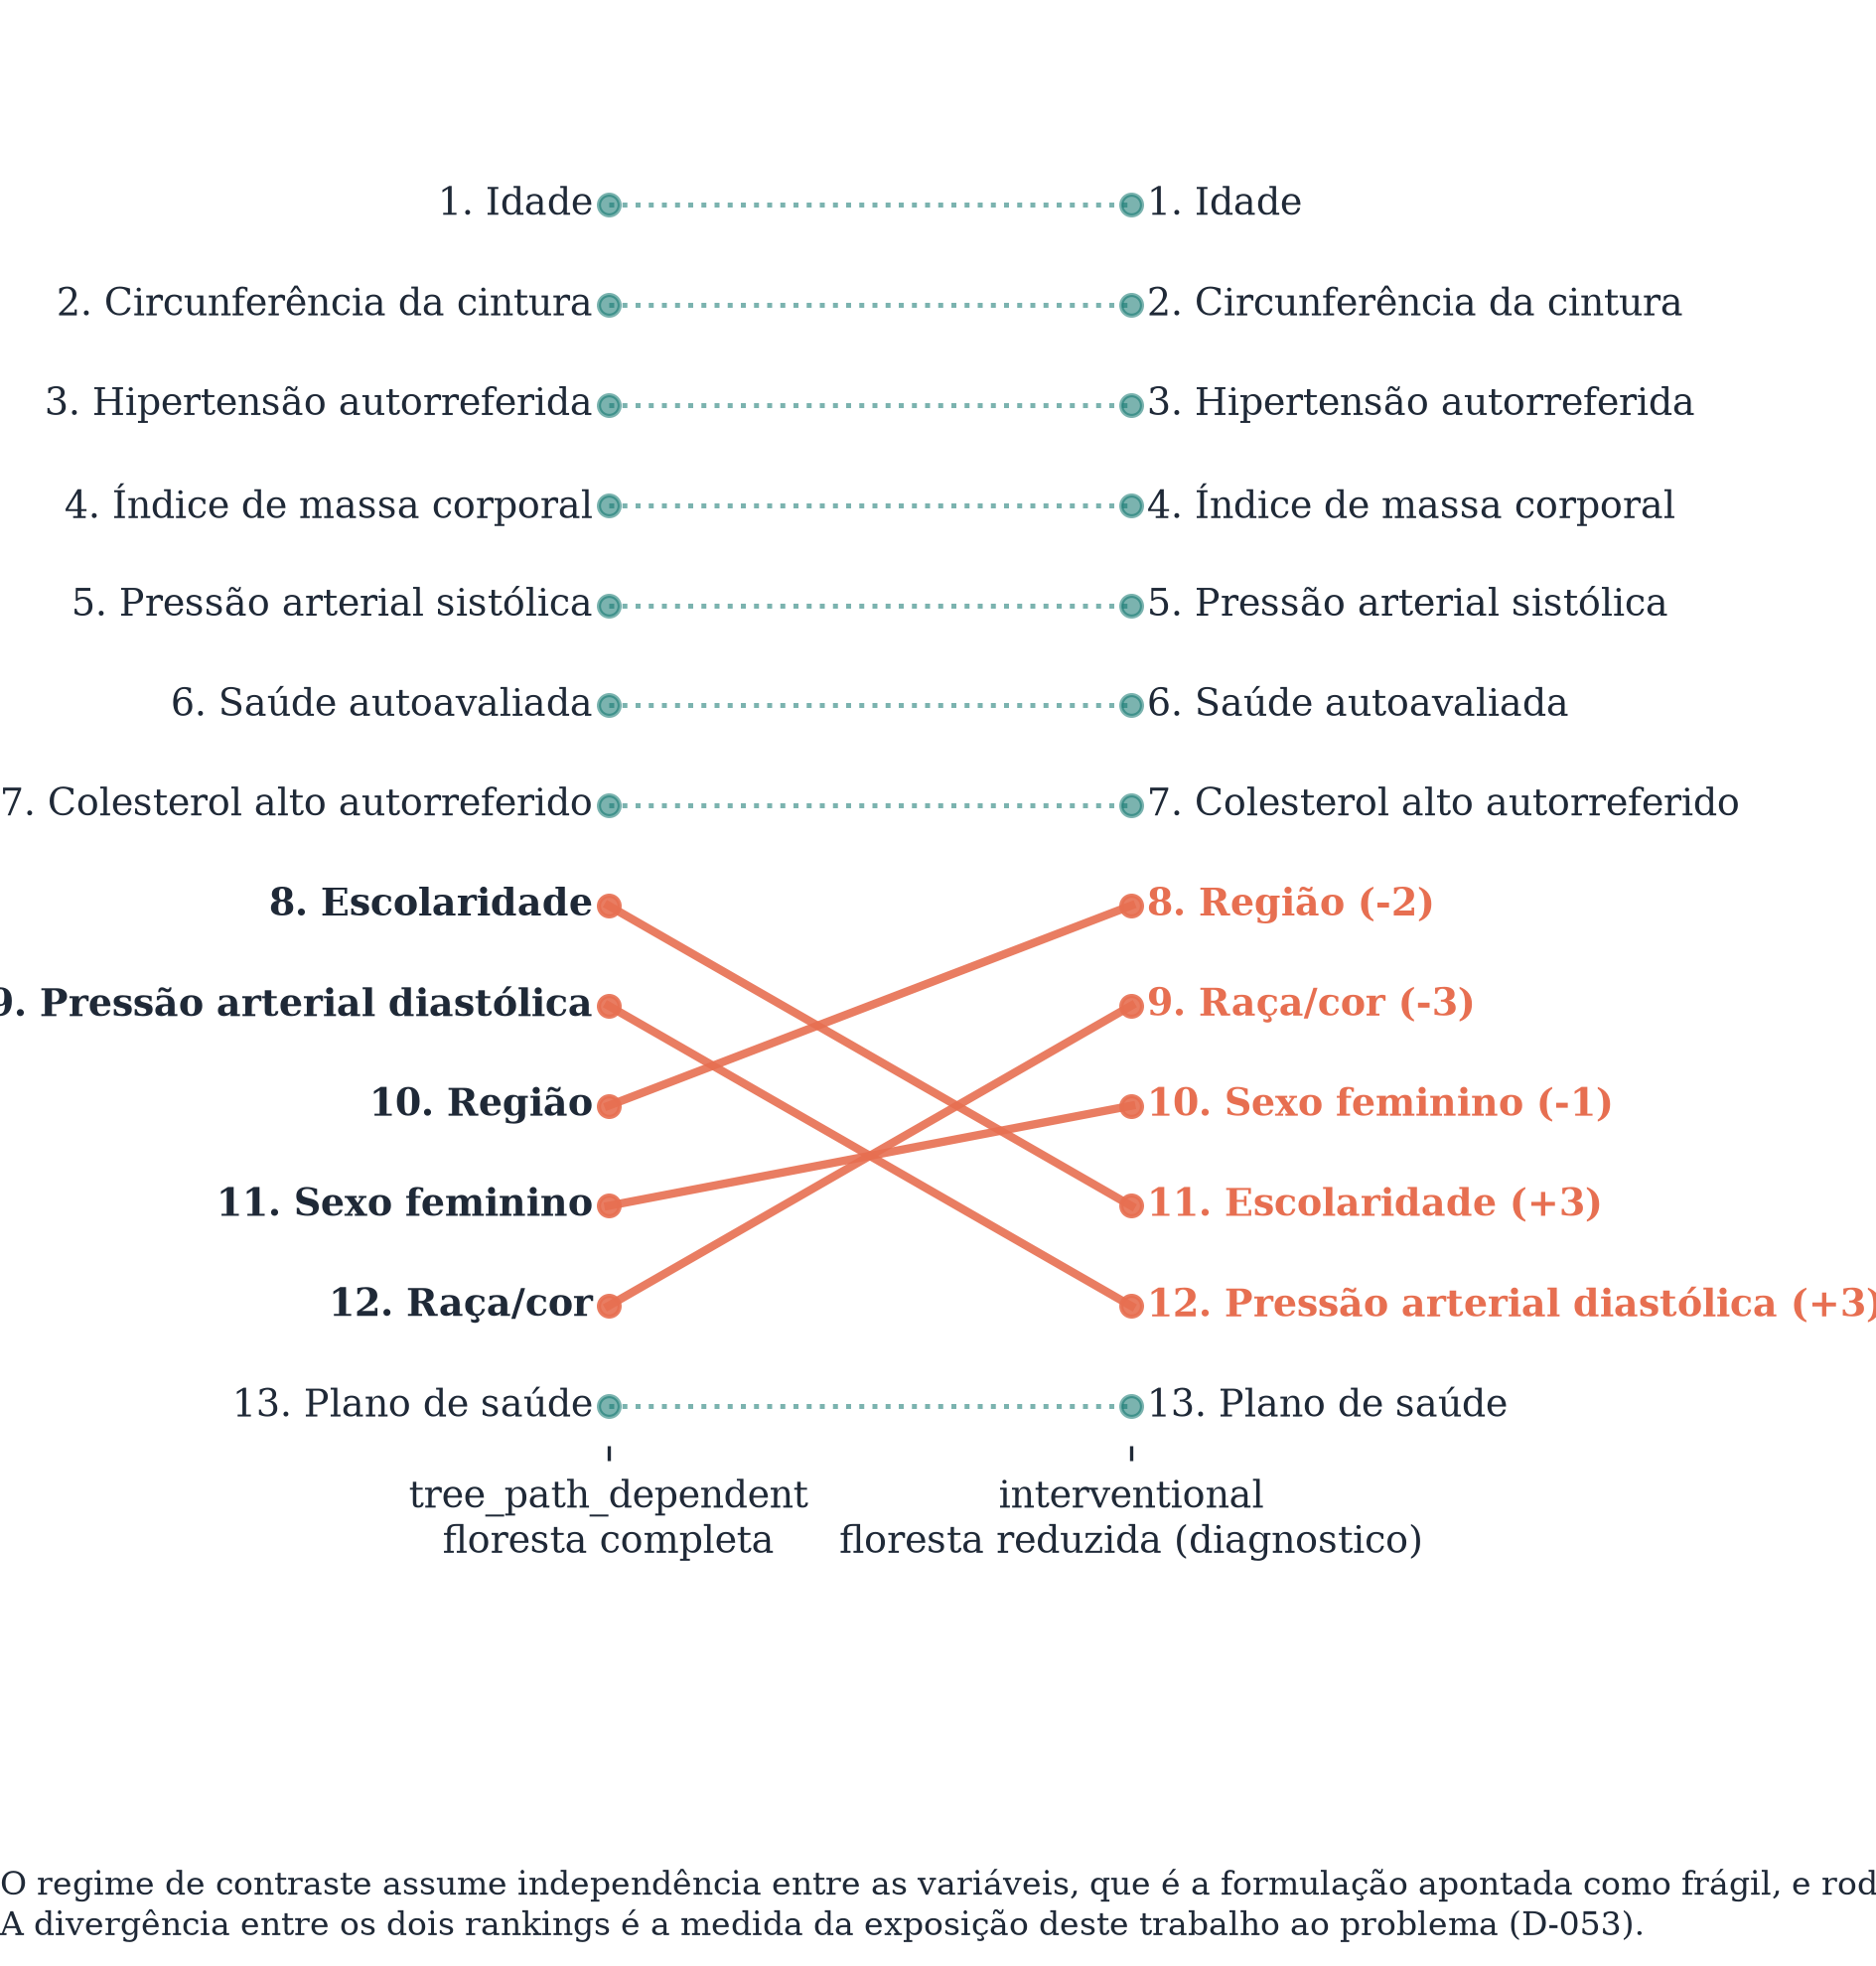

In [33]:
display(Image(filename=str(ex.figura_contraste_de_regimes("A_atomico"))))

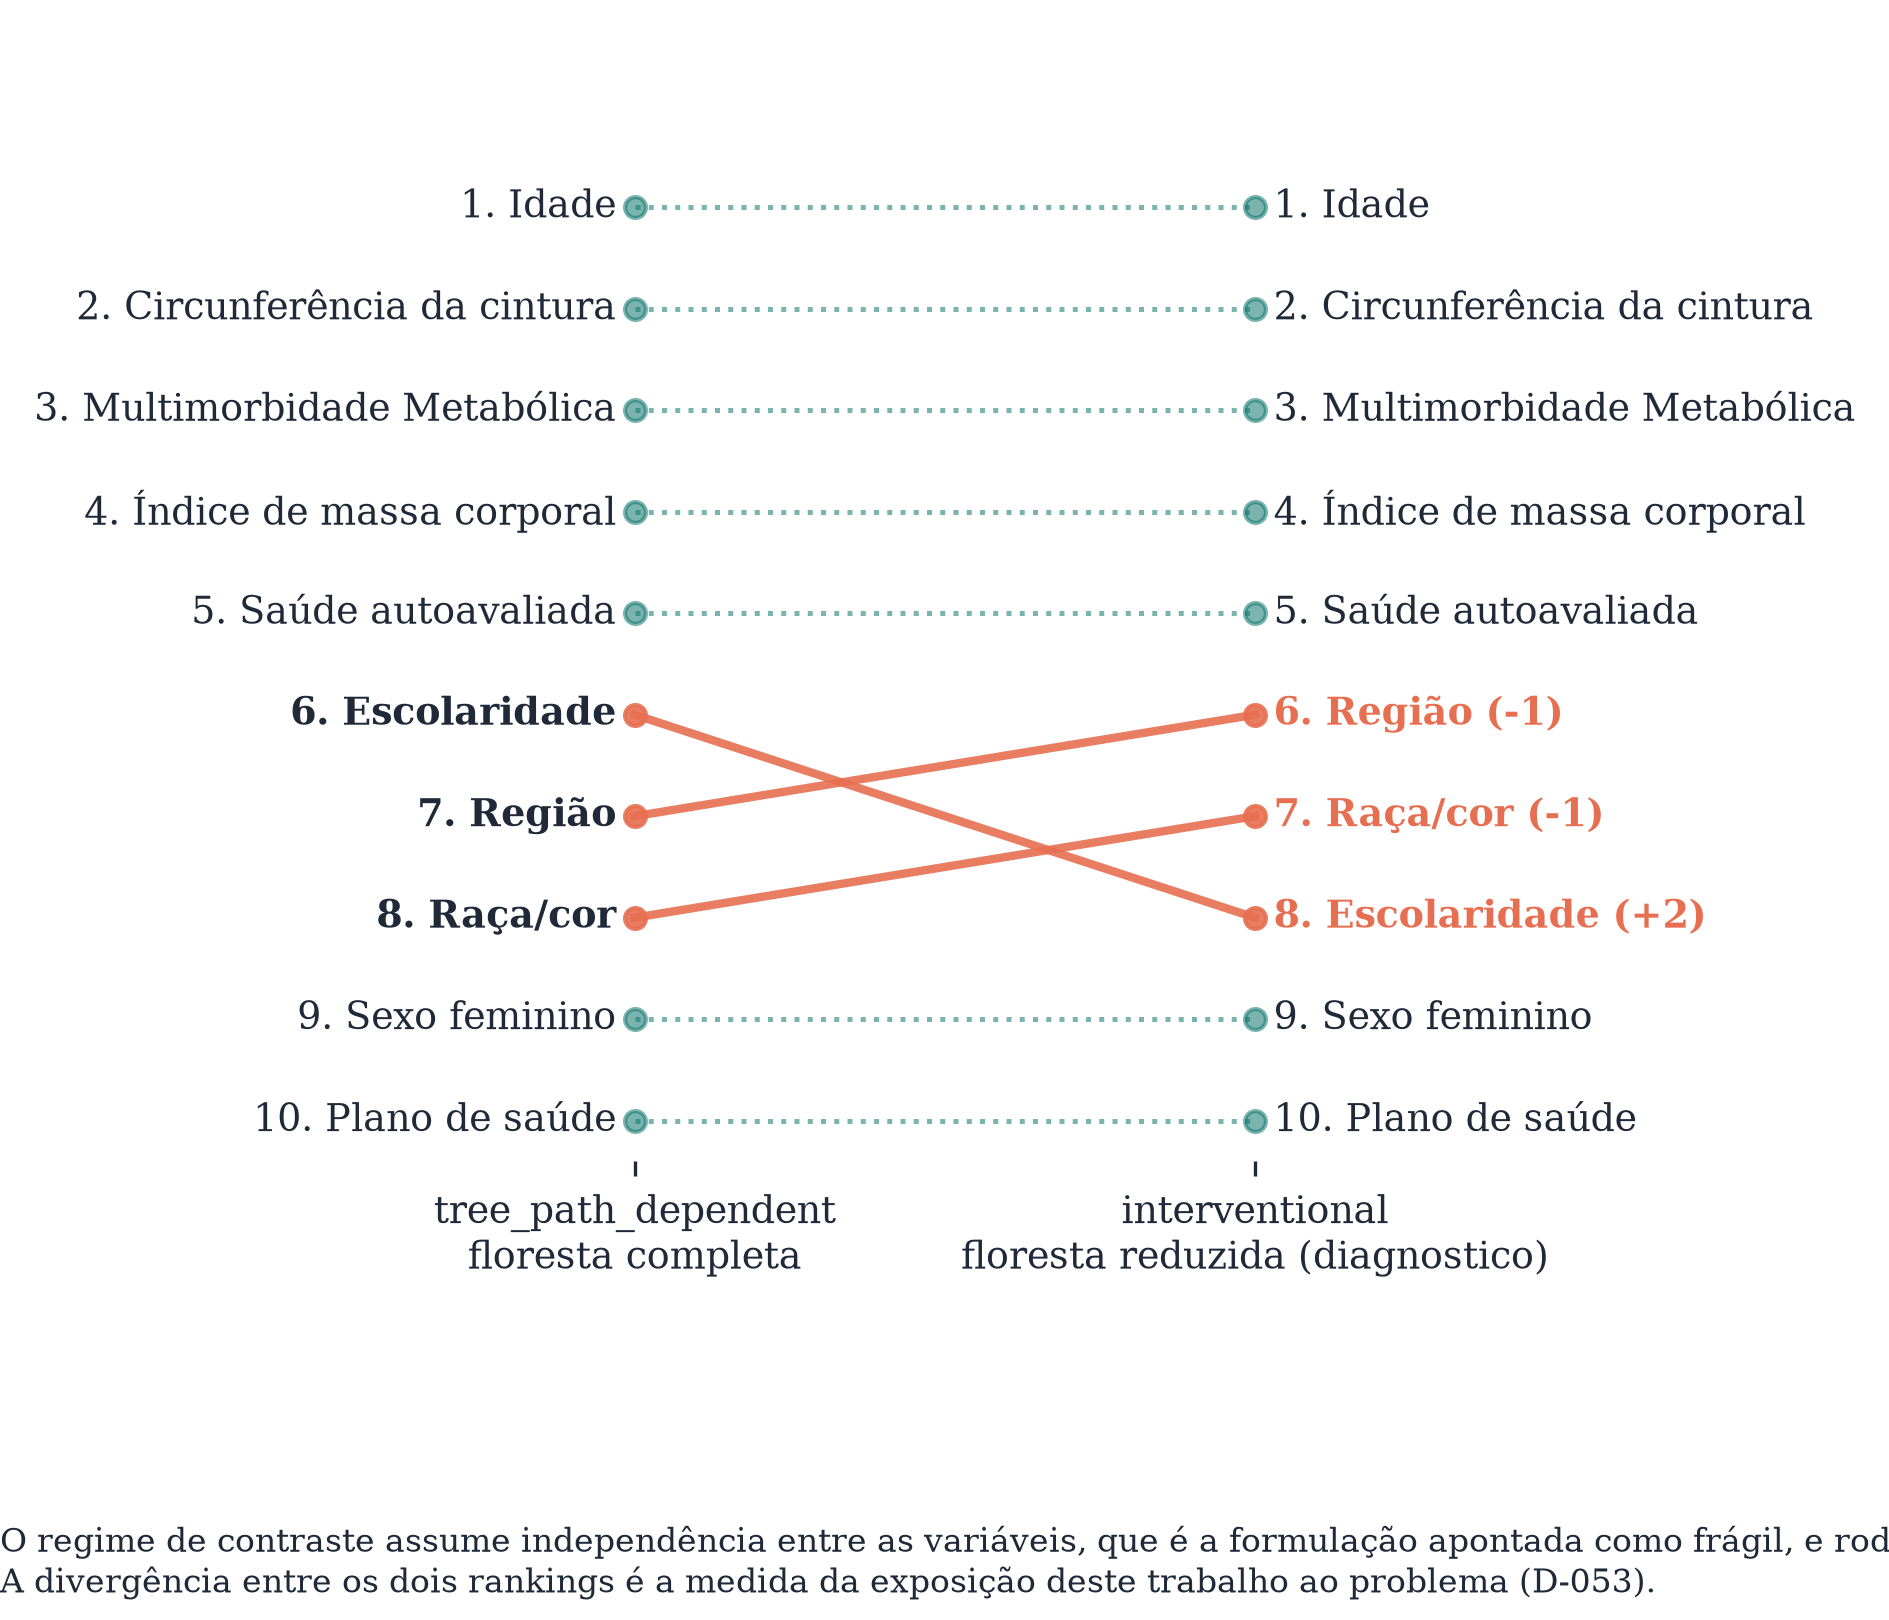

In [34]:
display(Image(filename=str(ex.figura_contraste_de_regimes("B_composto"))))

### A predição de D-053 e o que ela acertou

D-053 previu, antes de existir número, que dentro de cada par colinear um membro concentraria a atribuição e o outro colapsaria. **A predição falha em dois dos três blocos nomeados**, e o registro diz que falhou: predição declarada antes e refutada vale mais que ausência de predição.

Em `imc` × `circ_cintura` não há colapso. A divisão fica entre 36/64 e 38/62 nos dois conjuntos e nos dois regimes, com razão entre 1,66 e 1,91. No bloco de coarsening de `B_composto` também não: `multimorbidade` retém 34% da atribuição do bloco no regime principal e 32% no de contraste, contra 38% e 40% de `circ_cintura`. Em `pas` × `pad` a predição se confirma como assimetria e não como colapso, 75/25 no regime principal e 80/20 no de contraste, com `pad` caindo da nona para a décima segunda posição. A direção é a que a referência descreve e o efeito se acentua sob independência, que é o mecanismo previsto.

**Consequência para D-012.** A atribuição contraria o risco que aquele registro levanta. O escore não é recuperado linearmente a ponto de se esvaziar: ele carrega um terço do bloco por conta própria.

Dois achados ficam fora do pré-registro e entram **marcados como exploratórios**. Sob o regime de contraste, `escolaridade` perde 43% da atribuição em `A_atomico` e 44% em `B_composto`, contra a queda geral de 15% a 25%, enquanto `regiao` perde 9% e 7% e `raca_cor` sobe 5% e fica estável. E `raca_cor_3` tem atribuição de 1,0e-04 em `A_atomico` e 1,7e-04 em `B_composto`, penúltima posição nas duas, enquanto no baseline da logística era o maior coeficiente do modelo: a instabilidade que D-007 registra não reproduz na floresta. Isso não fecha D-007, que trata do coeficiente da logística, e `raca_cor` é décima segunda de treze em `A_atomico`, o que não autoriza discurso sobre magnitude.

### Explicação local

Quatro casos por célula em `shap_casos_locais`, um por célula da matriz de confusão, cada um o de menor distância entre escore e limiar dentro da sua, com desempate pelo menor índice. A regra é um `argmin` e não admite julgamento, que é o que separa escolha de caso de escolha por conveniência.

As figuras trazem o verdadeiro positivo e o falso negativo, que são os dois que a triagem discute: mesmo desfecho observado, decisões opostas, escores a milésimos do limiar. O falso positivo e o verdadeiro negativo ficam na tabela.

**O que as figuras precisam dizer, e é decisão registrada em D-053, não escolha de apresentação.** O valor de base fica em 0,5 por efeito do reponderamento de classes, e não na prevalência de 7%: uma explicação local que começa em 0,5 e aparece sem essa ressalva é lida como meio a meio antes de olhar qualquer variável. A referência das contribuições é o indivíduo médio sob esse reponderamento, e não a população, de modo que contribuição negativa significa abaixo dessa referência e nunca efeito protetor. O valor observado de cada variável aparece ao lado da contribuição, e o limiar da célula aparece marcado, porque é ali que a decisão acontece.

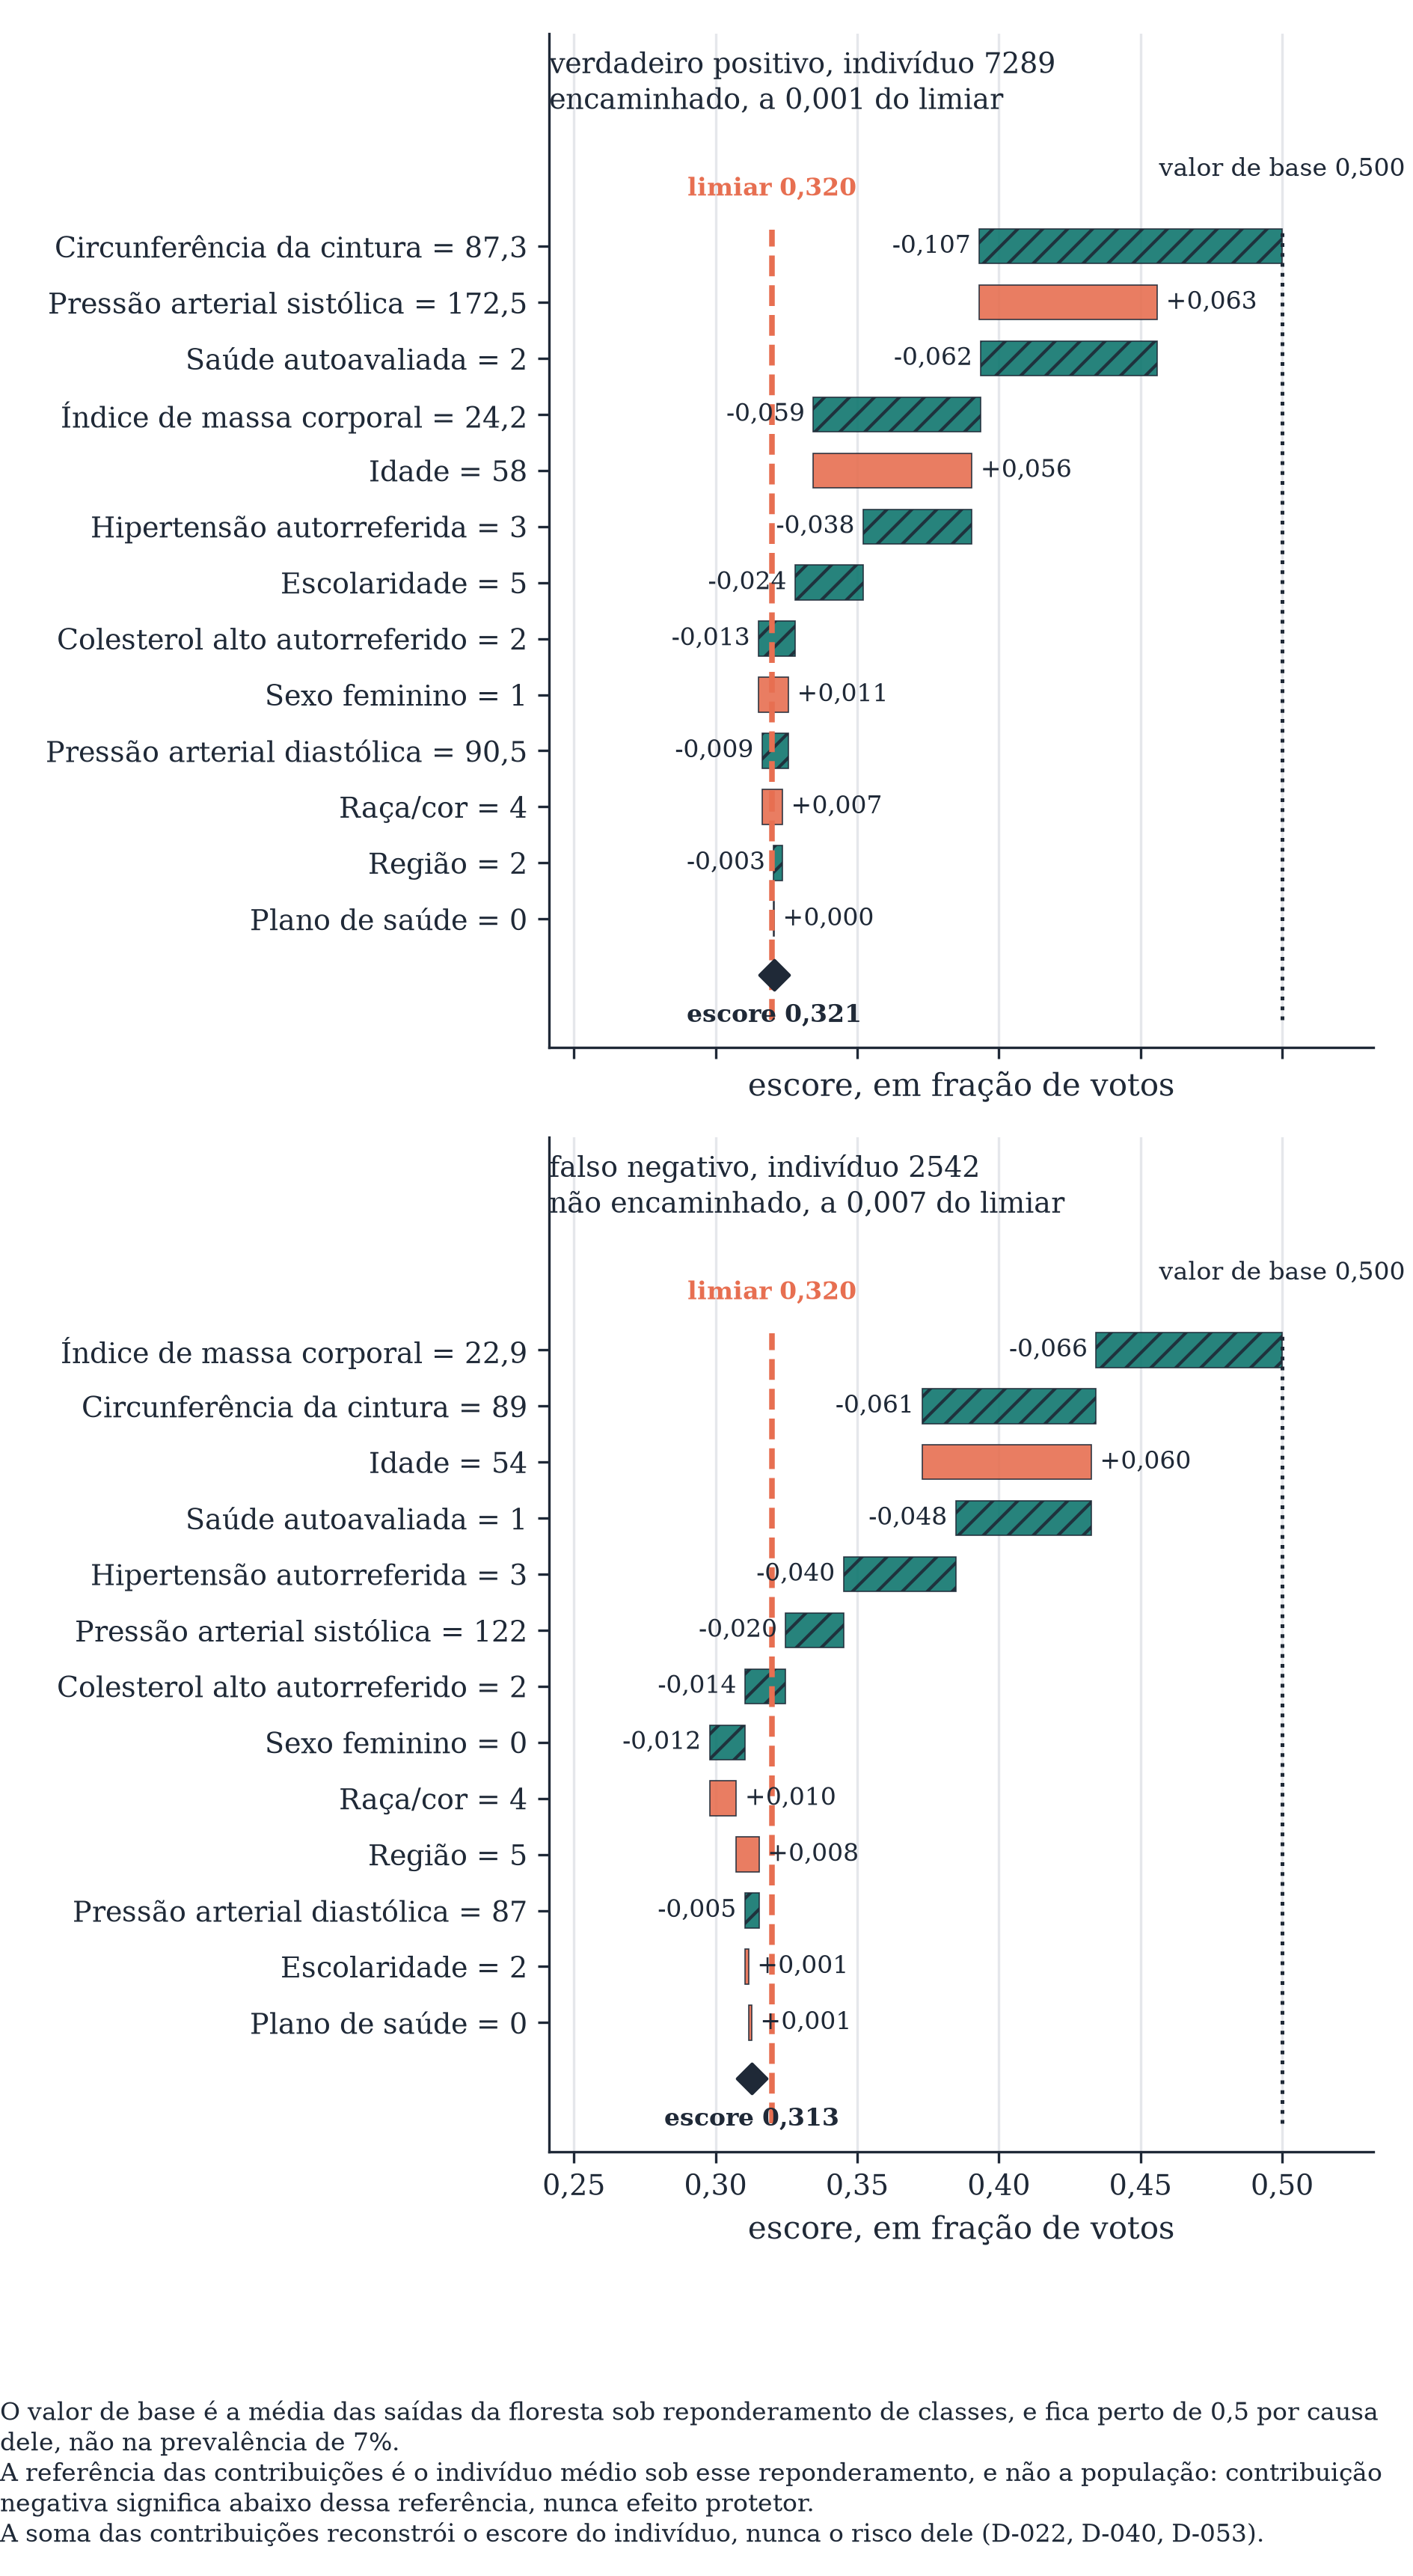

In [35]:
display(Image(filename=str(ex.figura_waterfall_par(material["A_atomico"]))))

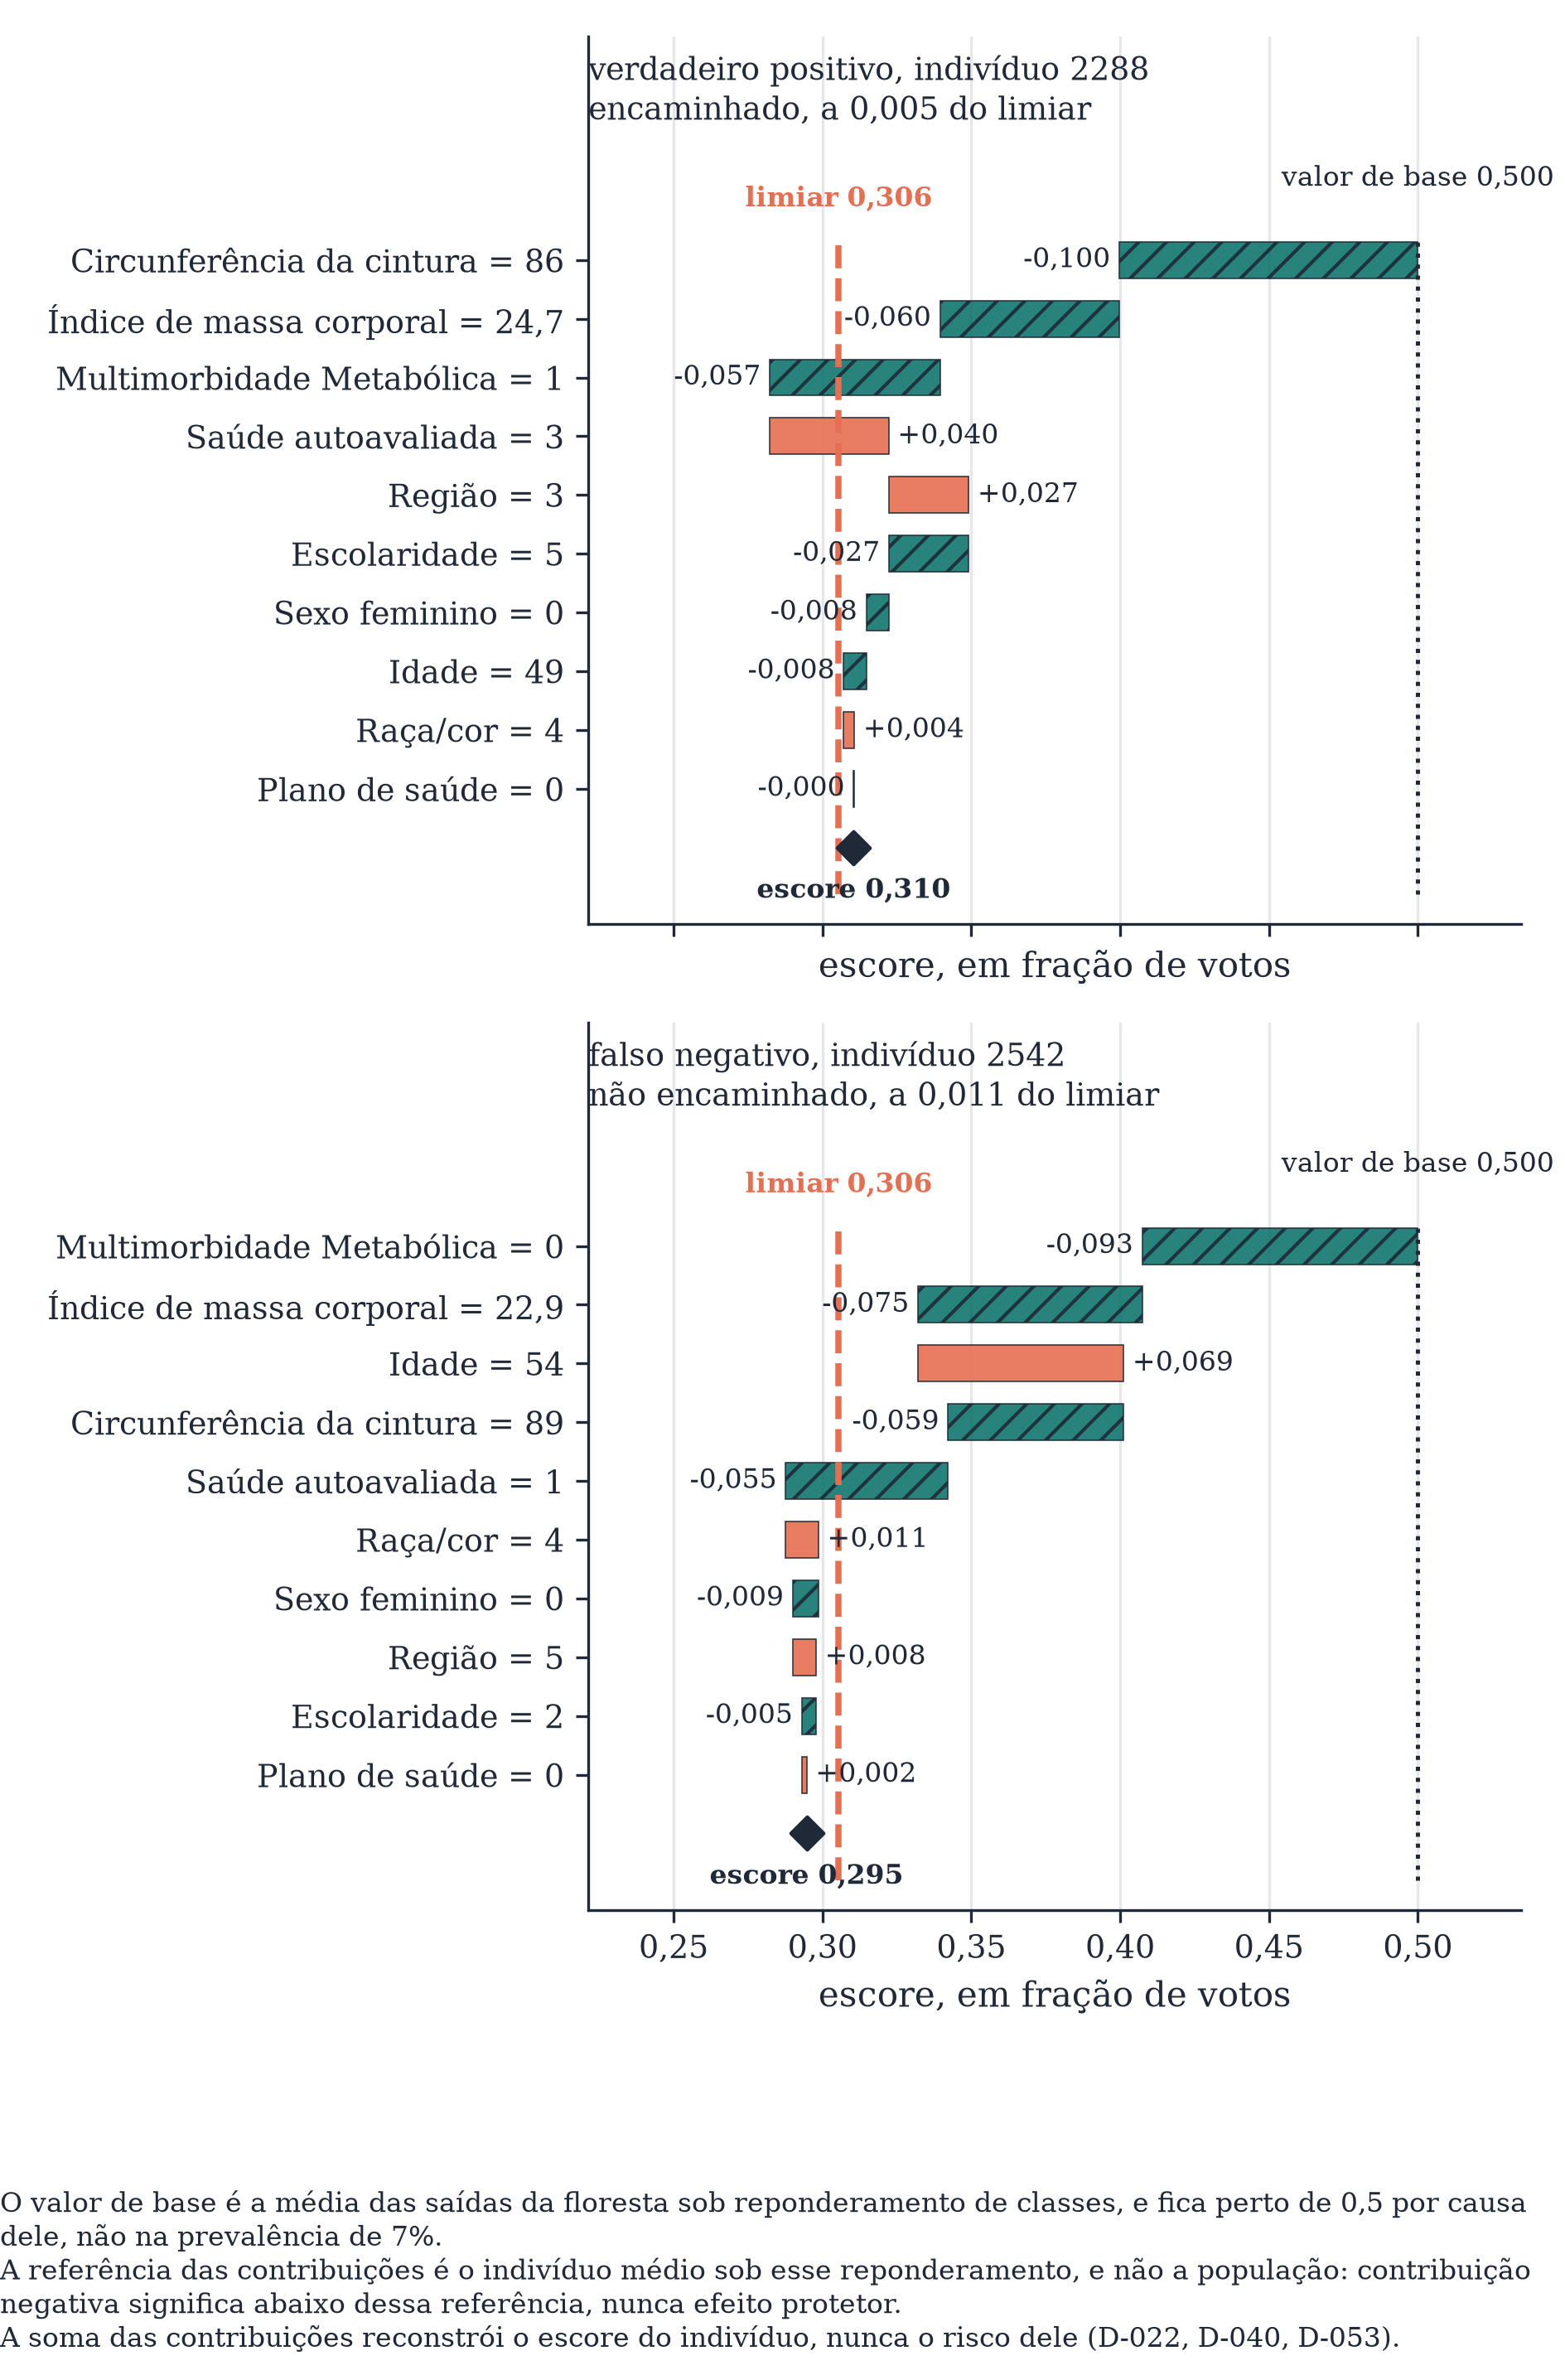

In [36]:
display(Image(filename=str(ex.figura_waterfall_par(material["B_composto"]))))

### Aditividade conferida, e o defeito que ela encontrou

A aditividade foi conferida em vez de presumida. No regime principal ela fecha com folga, na ordem de 1e-15. No de contraste não fecha com esta versão do explicador, e a causa foi localizada até a árvore: explicadas isoladamente sobre o teste completo, 121 árvores erram em `A_atomico` e 72 em `B_composto`, e os dois grupos ficam separados por milhares de vezes. As mesmas árvores são exatas sob o regime principal, então o modelo está correto e quem erra é o algoritmo do explicador.

O contraste roda sobre a floresta sem essas árvores. **Ela é objeto de diagnóstico e nunca modelo publicado**: o SHAP global publicado é o `tree_path_dependent` sobre as 500 árvores. `delta_arvores` é o deslocamento de ranking que a remoção causa, `delta_regime` é o que o regime causa, e é a comparação entre os dois que sustenta emitir o contraste assim (D-053).

In [37]:
ex.ler_tabela(ex.NOME_ARVORES)

,celula,regime_principal,regime_contraste,arvores_ajustadas,arvores_mantidas,arvores_excluidas,corte,erro_min_mantidas,erro_max_mantidas,erro_min_excluidas,erro_max_excluidas,piso_por_arvore,erro_aditividade_principal,erro_aditividade_contraste,delta_arvores,delta_regime
0,A_atomico,tree_path_dependent sobre floresta completa,interventional sobre floresta reduzida (diagno...,500,379,121,0.0001,3.970000e-08,8.820000e-08,0.000408,0.804,5.900000e-08,1.000000e-15,1.000000e-08,2,14
1,B_composto,tree_path_dependent sobre floresta completa,interventional sobre floresta reduzida (diagno...,500,428,72,0.0001,3.820000e-08,8.760000e-08,0.001670,0.838,5.770000e-08,1.000000e-15,1.000000e-08,0,4
